
# **Hotel Reviews and Wages in the United States**

**Course:** BA780  
**Report:** Team Assignment

Source: https://www.kaggle.com/datasets/datafiniti/hotel-reviews?resource=download

License: CC BY-NC-SA 4.0
(add wages dataset plus license)

This report explores hotel review records and wage differences across selected job records. The two datasets are studied separately in this phase.

# Do Higher Hospitality Wages Lead to Better Hotel Ratings?

*Hotel reviews and hospitality wages across U.S. states*

**Team B07:** Anna Zvanskaya, Pushan Parihr, Sharanya Srinivas  
**Course:** BA780 Introduction to Data Analytics, Final Project

**Data sources**
- **Hotel reviews:** Datafiniti Hotel Reviews, Kaggle: https://www.kaggle.com/datasets/datafiniti/hotel-reviews (License: CC BY-NC-SA 4.0)
- **Wages:** U.S. Bureau of Labor Statistics, Occupational Employment and Wage Statistics, May 2013: https://www.bls.gov/oes/tables.htm (public domain, U.S. government data)

## **Executive Summary**:




 This project analyzed 55,912 hotel reviews and U.S. hospitality wage data to understand customer satisfaction and it's relationship with employee wages. After cleaning and removing duplicates, 55,698 reviews remained for analysis.

The results show that cleanliness was the most common issue in low-rated reviews, followed by room comfort and facility-related problems, however the data mentioning staff and service, which is the information of interest for our study, only made up 0.5% of reviews. Customer satisfaction remained relatively stable, with only small fluctuations in average ratings. Hospitality wages also varied noticeably across states, with the District of Columbia, Massachusetts, and New York among the highest-paying areas.

Overall, the findings suggest that improving cleanliness, room quality, and service consistency could have the strongest impact on guest satisfaction. However it would be important to gather more data on staff and service in order to have a better understanding of how these aspects affect customer satisfaction. Wage differences were observed across states, however our analysis wasn't able to establish a direct relationship between higher wages and better hotel ratings.

## 1. Introduction and Motivation
Hotel reviews are one of teh main criteria fro trabelers while choosing their stay, so for hotels rating have direct affect on their revenue.

A common belief is that better-paid staff deliver better service, which should lead to higher customers' satisfuction. If that is true, higher wages would be an investment in ratings, not just a cost. If it is not true, some of the money spent on wages raise would be better spent elsewhere.

This report tests that belief with real data. We combine more than 35,000 hotel reviews with government wage data for hospitality workers across U.S. states. We look at what guests complain about, how ratings differ between states, and whether states that pay more have better-rated hotels.

This analysis can gives hotel managers, HR teams and hospitality investors evidence on where spending is most likely to improve guest ratings. It also shows which guest complaints hurt ratings the most. And can set the direction for further exploration.

## 2. Problem Definition:

Problem Definition
This project examines hotel customer satisfaction and explores whether hospitality wages are related to hotel ratings across U.S. states. The results can help hotel managers, housekeeping teams, customer-service teams, and HR departments improve hotel operations.
We will:
- Clean missing values and remove duplicate records.
- Identify common causes of low hotel ratings, including staff service, cleanliness, and room quality.
- Compare hotel ratings and customer complaints across states.
- Compare hospitality wages across U.S. states.
- Examine whether higher hospitality wages are associated with better hotel ratings.
- Join the hotel review data with the wage data using state location.

This project will be successful if we can clearly organize the data, explain the rating scale, identify common guest complaints, create understandable visualizations, and provide conclusions that help hotel managers make better decisions.


## 3. Data Sources and Scope

### 3.1 Input Files

The saved outputs show the following original file sizes. A hotel review row is one supplied review record. A wage row describes an occupation for an area, industry, and ownership group.

| Input file | Original rows | Original columns | Source information |
| --- | ---: | ---: | --- |
| `Datafiniti_Hotel_Reviews.csv` | 10,000 | 25 | Datafiniti hotel review sample; see the related dataset listing in References. |
| `Datafiniti_Hotel_Reviews_Jun19.csv` | 10,000 | 26 | Second Datafiniti sample; confirm the exact export date and download link. |
| `7282_1.csv` | 35,912 | 19 | Legacy review file; its exact source and rating scales need confirmation. |
| `780_data_wages_01.xlsx` | 434,473 | 29 | Identified by the team as 2013 occupational employment and wage data; see the BLS tables and workbook field descriptions. |

**Source details to complete:** Add the team's exact download links, access dates, and license or reuse terms for the supplied files. A related source page does not confirm the provenance of every local file.

### 3.2 Main Fields

| Field | Meaning | How it is used |
| --- | --- | --- |
| `reviews_rating` | Recorded review score | Rating comparisons; the legacy scale is unverified. |
| `reviews_date` | Review date | Group reviews by year. |
| `reviews_text` | Review text | Find selected complaint phrases. |
| `province` | Hotel state or province code in the record | Group reviews by location; location accuracy still needs checking. |
| `source_file`, `source_row` | Original file and record number | Trace a review back to its source. |
| `area_title` | Area name in the wage file | Group wage records by state or district. |
| `occ_title` | Occupation title | Select hotel and food service related titles. |
| `a_mean` | Mean annual wage for an occupation record, in dollars | Calculate the wage averages shown in Question 1. |

### 3.3 Analysis Scope

| Question | Records used | Important limit |
| --- | --- | --- |
| Q1: Wage differences | Cleaned wage records for selected detailed occupation titles | The mean is not weighted by the number of workers. |
| Q2: State scores | Cleaned `7282` records, U.S. state codes, scores from 0 to 10, at least 30 reviews | Different score scales may be mixed. |
| Q3: Complaint keywords | Cleaned `7282` records with text and scores from 1 to 3 | Phrase matches do not capture every complaint. |
| Q4: Yearly scores | Raw `7282` records from 2011 to 2016 with scores from 1 to 5 | These records are not the combined cleaned table; the scale is still unverified. |
| Q5: Review counts | Raw `Datafiniti_Hotel_Reviews.csv` records | Counts describe this sample, not hotel demand. |

**Summary:** The three review files contain 55,912 original records, and the wage file contains 434,473 records. The charts use different subsets, so their results should be read with the scope shown above.



### 3.4 Run Instructions

1. Put the three original CSV files and `780_data_wages_01.xlsx` in the notebook's working folder. In Colab, upload all four files in the Files panel before running the notebook.
2. Run the setup cell below, then continue from top to bottom. Filenames with copy suffixes such as `(1)` or `(2)` are accepted when there is one clear match.
3. The notebook needs Python, pandas 2.0 or later, NumPy, Matplotlib, Seaborn, and openpyxl. If a package is missing, install it before starting.
4. Results are written to `hotel_cleaning_outputs` and `Hotel_Reviews_Cleaned_Results.zip`. Automatic downloads are off; set `AUTO_DOWNLOAD = True` if you want them in Colab.
5. Before submission, restart the kernel and run all cells. Save the refreshed tables and charts with the notebook.


# 4. Data Cleaning:
We clean the hotel review files first, then the wage file. Original values and flags are kept where the code provides them, so important source issues remain visible.

### 4.1 Hotel Review Data

#### Step 1 - Import files

In [ ]:
import pandas as pd
from google.colab import files
from pathlib import Path
import re
import shutil
import json
import io
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
#from google.colab import files
#uploaded = files.upload()

In [ ]:
reviews_file1 = pd.read_csv('Datafiniti_Hotel_Reviews.csv')
reviews_file2 = pd.read_csv('Datafiniti_Hotel_Reviews_Jun19.csv')
reviews_file3 = pd.read_csv('7282_1.csv')

raw = {'Datafiniti_Hotel_Reviews.csv': reviews_file1,
       'Datafiniti_Hotel_Reviews_Jun19.csv': reviews_file2,
       '7282_1.csv': reviews_file3}

print('Pandas version:', pd.__version__)
print(reviews_file1.shape)
print(reviews_file2.shape)
print(reviews_file3.shape)
print('Total original rows:', len(reviews_file1) + len(reviews_file2) + len(reviews_file3))

Pandas version: 2.2.3
(10000, 25)
(10000, 26)
(35912, 19)
Total original rows: 55912


Summary: Three hotel review CSV files were loaded, containing 55,912 records in total. All fields were read as text to preserve identifiers and codes with leading zeros.

#### Step 2 - Inspect the Files


Check row counts, columns and exact duplicates. We inspect all rows, not just a sample. The files have different schemas, so they cannot simply be treated as identical tables.
An empty cell is missing information; it is not a zero rating or a negative review.


In [ ]:
initial_profile = pd.DataFrame({
    'source_file': ['Datafiniti_Hotel_Reviews.csv',
                    'Datafiniti_Hotel_Reviews_Jun19.csv',
                    '7282_1.csv'],
    'original_rows': [reviews_file1.shape[0], reviews_file2.shape[0], reviews_file3.shape[0]],
    'original_columns': [reviews_file1.shape[1], reviews_file2.shape[1], reviews_file3.shape[1]],
    'exact_duplicates': [reviews_file1.duplicated().sum(),
                         reviews_file2.duplicated().sum(),
                         reviews_file3.duplicated().sum()]
})

display(initial_profile)

,source_file,original_rows,original_columns,exact_duplicates
0,Datafiniti_Hotel_Reviews.csv,10000,25,0
1,Datafiniti_Hotel_Reviews_Jun19.csv,10000,26,210
2,7282_1.csv,35912,19,4


In [ ]:
for name in raw.keys():
    df = raw[name]
    print()
    print(name)
    print(df.columns)
    print('Most common rating values:')
    print(df['reviews.rating'].value_counts().head(12))
    print('Missing ratings:', df['reviews.rating'].isnull().sum())


Datafiniti_Hotel_Reviews.csv
Index(['id', 'dateAdded', 'dateUpdated', 'address', 'categories',
       'primaryCategories', 'city', 'country', 'keys', 'latitude', 'longitude',
       'name', 'postalCode', 'province', 'reviews.date', 'reviews.dateSeen',
       'reviews.rating', 'reviews.sourceURLs', 'reviews.text', 'reviews.title',
       'reviews.userCity', 'reviews.userProvince', 'reviews.username',
       'sourceURLs', 'websites'],
      dtype='object')
Most common rating values:
reviews.rating
5.00    4384
4.00    2397
3.00    1187
1.00     572
2.00     561
4.80     162
4.60     155
4.40     102
3.75      91
4.15      78
3.95      52
3.55      50
Name: count, dtype: int64
Missing ratings: 0

Datafiniti_Hotel_Reviews_Jun19.csv
Index(['id', 'dateAdded', 'dateUpdated', 'address', 'categories',
       'primaryCategories', 'city', 'country', 'keys', 'latitude', 'longitude',
       'name', 'postalCode', 'province', 'reviews.date', 'reviews.dateAdded',
       'reviews.dateSeen', 'reviews.r

Summary: The datasets had 25, 26, and 19 columns and 214 exact duplicate records. The 7282 dataset had missing ratings and scores outside the five-star range, where 1 is lowest and 5 is highest.

#### Step 3 - Remove Identical Rows and Rename Columns
`reviews.rating` becomes `reviews_rating`, which is easier to use in code. Duplicate removal happens before cleaning, using all original fields within each file. This avoids accidentally merging distinct reviews that happen to share text.

We add `source_file` and `source_row`: the latter is the 1-based data-record number, excluding the header (not a physical line number, because text can contain newlines). Removed records are saved in a separate audit file.


In [ ]:
rename_cols = {'reviews.date': 'reviews_date',
               'reviews.dateadded': 'reviews_dateadded',
               'reviews.dateseen': 'reviews_dateseen',
               'reviews.dorecommend': 'reviews_dorecommend',
               'reviews.id': 'reviews_id',
               'reviews.rating': 'reviews_rating',
               'reviews.sourceurls': 'reviews_sourceurls',
               'reviews.text': 'reviews_text',
               'reviews.title': 'reviews_title',
               'reviews.usercity': 'reviews_usercity',
               'reviews.userprovince': 'reviews_userprovince',
               'reviews.username': 'reviews_username'}

cleaned = {}
removed_duplicates = []
column_mapping = []

for name in raw.keys():
    original = raw[name]

    dup = original.duplicated()
    removed = original[dup].copy()
    removed['source_file'] = name
    removed['source_row'] = removed.index + 1
    removed_duplicates.append(removed)

    df = original[~dup].copy()
    old_names = df.columns
    df.columns = df.columns.str.lower()
    df = df.rename(columns=rename_cols)

    column_mapping.append(pd.DataFrame({'source_file': name,
                                        'original_column': old_names,
                                        'clean_column': df.columns}))

    df['source_file'] = name
    df['source_row'] = df.index + 1
    cleaned[name] = df.reset_index(drop=True)

removed_all = pd.concat(removed_duplicates, ignore_index=True)
mapping_all = pd.concat(column_mapping, ignore_index=True)

total_rows = 0
for name in cleaned.keys():
    total_rows = total_rows + len(cleaned[name])

print('Exact duplicate rows removed:', len(removed_all))
print('Rows remaining:', total_rows)

Exact duplicate rows removed: 214
Rows remaining: 55698


Summary: We removed 214 rows that were exactly the same, leaving 55,698 reviews. We made column names simpler and added file names and also original row numbers to show where each review came from.

#### Step 4 - Clean Spaces and Mark Missing Values

Trim leading and trailing whitespace. Turn empty strings into missing values. For review text/title and reviewer location/name fields only, treat exact tokens `NA`, `N/A`, `null`, `none`, and `nan` as missing.

Collapse repeated whitespace inside review text/title. Kept punctuation, capitalization, emojis and stop words: these may matter for sentiment. Preserve raw text/title alongside the cleaned version. Do not invent missing reviews, ratings or reviewer locations. All-empty columns stay available and are reported.


In [ ]:
text_columns = ['address', 'categories', 'city', 'country', 'name', 'province',
                'reviews_text', 'reviews_title', 'reviews_usercity',
                'reviews_userprovince', 'reviews_username']

token_columns = ['reviews_text', 'reviews_title', 'reviews_usercity',
                 'reviews_userprovince', 'reviews_username']

missing_words = ['na', 'n/a', 'null', 'none', 'nan']

whitespace_changes = []

for name in cleaned.keys():
    df = cleaned[name]

    df['reviews_text_raw'] = df['reviews_text'].copy()
    df['reviews_title_raw'] = df['reviews_title'].copy()

    count = 0
    for col in text_columns:
        if col in df.columns:
            before = df[col].copy()

            df[col] = df[col].str.strip()
            df.loc[df[col] == '', col] = pd.NA

            if col in token_columns:
                df.loc[df[col].str.lower().isin(missing_words), col] = pd.NA

            changed = before.fillna('<MISSING>') != df[col].fillna('<MISSING>')
            count = count + changed.sum()

    whitespace_changes.append({'source_file': name, 'cells_cleaned_or_marked_missing': count})
    df['country'] = df['country'].str.upper()

display(pd.DataFrame(whitespace_changes))

,source_file,cells_cleaned_or_marked_missing
0,Datafiniti_Hotel_Reviews.csv,4
1,Datafiniti_Hotel_Reviews_Jun19.csv,0
2,7282_1.csv,10


Summary: We removed extra spaces and marked empty cells or words like “N/A” as missing. We kept copies of the original reviews and titles and kept capital letters and emojis. Also, the median wage is calculated only among the states left in the analysis, after dropping states with fewer than 100 reviews and states that didn’t match between the two datasets. So “high” and “low” are relative to the states in your graph, not all 50. And the "low" vs "high" wages are calculated by taking the median wages across states, and everything below it is low and everything above it is high.

#### Step 5 - Convert numeric fields and check rating scales
Convert latitude, longitude and rating into numbers with `pd.to_numeric`. Preserve the original values and flag failed conversions. Coordinates outside −90…90 or −180…180 are set to missing in the cleaned numeric field.

**Important discovery:** the 7282 file contains both 1–5 and higher scores, plus zeros. The files do not provide enough information to establish each legacy row's scale. We flag every legacy rating as scale-unverified and keep the original number. We do not divide just the values above 5, clip scores, or replace zeros with a guessed score.

The two Datafiniti files have values compatible with 1–5; this is an observed range, not proof of a documented scale. Confirm source documentation before calculating pooled rating averages. Decimal scores are retained.


In [ ]:
summary = []

for name in cleaned.keys():
    df = cleaned[name]

    for col in ['latitude', 'longitude', 'reviews_rating']:
        df[col + '_raw'] = df[col].copy()
        numeric = pd.to_numeric(df[col], errors='coerce')
        df[col + '_parse_failed'] = df[col].notna() & numeric.isna()
        df[col] = numeric

    bad_lat = df['latitude'].notna() & ~df['latitude'].between(-90, 90)
    df['latitude_out_of_range'] = bad_lat
    df.loc[bad_lat, 'latitude'] = np.nan

    bad_long = df['longitude'].notna() & ~df['longitude'].between(-180, 180)
    df['longitude_out_of_range'] = bad_long
    df.loc[bad_long, 'longitude'] = np.nan

    if '7282' in name:
        df['rating_scale_status'] = 'mixed_or_unknown_scale'
    else:
        df['rating_scale_status'] = 'observed_1_to_5_documentation_unverified'

    rating = df['reviews_rating']
    df['rating_outside_1_to_5'] = rating.notna() & ~rating.between(1, 5)

    summary.append({'source_file': name,
                    'min_rating': rating.min(),
                    'max_rating': rating.max(),
                    'missing_rating': rating.isna().sum(),
                    'outside_1_to_5': df['rating_outside_1_to_5'].sum()})

display(pd.DataFrame(summary))

,source_file,min_rating,max_rating,missing_rating,outside_1_to_5
0,Datafiniti_Hotel_Reviews.csv,1.0,5.0,0,0
1,Datafiniti_Hotel_Reviews_Jun19.csv,1.0,5.0,0,0
2,7282_1.csv,0.0,10.0,862,694


**Summary:** We changed ratings and location values into numbers and marked errors. The 7282 file had 862 missing ratings and 694 scores outside the five star range, where 1 is lowest and 5 is highest. We kept the original scores because their rating scale was unclear.

#### Step 6 — Convert dates and keep an audit trail
Use UTC datetimes and retain the original values. `errors='coerce'` converts an unparseable date to `NaT`; a separate flag records the failure so it cannot disappear silently. Future review dates are flagged against a reproducible project cutoff.

`reviews_dateSeen` may contain a list of dates, so it is deliberately preserved as text. Do not treat a date list as a single timestamp. Missing dates stay missing; do not fill them with today's date.


In [ ]:
PROJECT_AS_OF = pd.Timestamp('2026-09-28 23:59:59', tz='UTC')
date_columns = ['dateadded', 'dateupdated', 'reviews_date', 'reviews_dateadded']

for name in cleaned.keys():
    df = cleaned[name]

    for col in date_columns:
        if col in df.columns:
            df[col + '_raw'] = df[col].copy()
            parsed = pd.to_datetime(df[col], errors='coerce', format='mixed', utc=True)
            df[col + '_parse_failed'] = df[col].notna() & parsed.isna()
            df[col] = parsed

    df['review_date_in_future'] = df['reviews_date'] > PROJECT_AS_OF
    df['review_year'] = df['reviews_date'].dt.year.astype('Int64')

    print(name)
    print('Missing review dates:', df['reviews_date'].isna().sum())
    print('Failed date conversions:', df['reviews_date_parse_failed'].sum())
    print()

Datafiniti_Hotel_Reviews.csv
Missing review dates: 0
Failed date conversions: 0

Datafiniti_Hotel_Reviews_Jun19.csv
Missing review dates: 0
Failed date conversions: 0

7282_1.csv
Missing review dates: 259
Failed date conversions: 0



Summary:
We changed dates to a standard date and time format and kept copies of the original values. All available review dates in the three files were converted without errors.

#### Step 7 — Combine a compact review table and flag possible overlap
The full cleaned files keep every original field. For analysis, build a smaller table with common review/hotel fields and provenance; fields absent from a source become missing.

Flag potential duplicates using hotel name, address, city, country, review text, date, username and numeric rating. All key fields must be present. Keep the candidates for manual review: matching content does not prove that two rows are the same review, and metadata can differ. This rule can miss duplicates with edited wording or missing keys.


In [ ]:
core_columns = ['source_file', 'source_row', 'id', 'name', 'address', 'city', 'country',
                'province', 'postalcode', 'latitude', 'longitude', 'reviews_date',
                'reviews_rating', 'reviews_text', 'reviews_title', 'reviews_username',
                'reviews_usercity', 'reviews_userprovince', 'rating_scale_status',
                'rating_outside_1_to_5', 'review_date_in_future', 'review_year']

tables = []
for name in cleaned.keys():
    tables.append(cleaned[name])

combined = pd.concat(tables, ignore_index=True)
combined = combined[core_columns].copy()

key_columns = ['name', 'address', 'city', 'country', 'reviews_text',
               'reviews_date', 'reviews_username', 'reviews_rating']
keys = combined[key_columns].copy()

for col in ['name', 'address', 'city', 'country', 'reviews_text', 'reviews_username']:
       keys[col] = keys[col].str.lower().str.split().str.join(' ')

complete_key = keys.isnull().sum(axis='columns') == 0
combined['potential_duplicate'] = complete_key & keys.duplicated(keep=False)

combined['missing_review_text'] = combined['reviews_text'].isna()
combined['review_word_count'] = combined['reviews_text'].str.split().str.len().astype('Int64')
combined['possibly_truncated_text'] = (combined['reviews_text'].str.contains('... More', regex=False, na=False) |
                                       combined['reviews_text'].str.contains('...More', regex=False, na=False))

print('Combined rows:', len(combined))
print('Rows in potential duplicate groups:', combined['potential_duplicate'].sum())
print('Rows missing review text:', combined['missing_review_text'].sum())
print('Possibly truncated review texts:', combined['possibly_truncated_text'].sum())

Combined rows: 55698
Rows in potential duplicate groups: 684
Rows missing review text: 28
Possibly truncated review texts: 10618



Summary:
We combined the cleaned files into one table with 55,698 reviews. We marked 684 rows that might be repeated and 10,536 reviews that might have missing endings.

#### Step 8 — Decide what to do with missing data
Do not drop rows because *any* column is missing: that would discard many usable reviews with missing reviewer locations. Keep a master table of all retained rows. For a text project, make a separate subset requiring nonmissing review text. The subset still contains flagged potential duplicates and possible truncation; inspect them for your specific analysis. If you later train a model, split by hotel/review groups to avoid overlap between training and test data.

No missing value is filled with a mean or an invented location. Missingness is reported per file and field. Absent source columns and empty source cells are distinguishable by consulting the original-column mapping.


In [ ]:
text_reviews = combined[~combined['missing_review_text']].copy()

reports = []
for name in cleaned.keys():
    df = cleaned[name]
    reports.append(pd.DataFrame({'source_file': name,
                                 'column': df.columns,
                                 'missing_count': df.isna().sum().values,
                                 'missing_percent': (df.isna().mean() * 100).round(2).values}))

missing_report = pd.concat(reports, ignore_index=True)

print('Text-analysis rows:', len(text_reviews))

missing_report = missing_report[missing_report['missing_count'] > 0]
display(missing_report.sort_values('missing_percent', ascending=False).head(20))

Text-analysis rows: 55670


,source_file,column,missing_count,missing_percent
93,Datafiniti_Hotel_Reviews_Jun19.csv,reviews_dateadded_raw,9790,100.00
62,Datafiniti_Hotel_Reviews_Jun19.csv,reviews_dateadded,9790,100.00
109,7282_1.csv,reviews_id,35908,100.00
108,7282_1.csv,reviews_dorecommend,35908,100.00
21,Datafiniti_Hotel_Reviews.csv,reviews_userprovince,7295,72.95
20,Datafiniti_Hotel_Reviews.csv,reviews_usercity,5837,58.37
113,7282_1.csv,reviews_usercity,19646,54.71
115,7282_1.csv,reviews_userprovince,18390,51.21
112,7282_1.csv,reviews_title,1630,4.54
119,7282_1.csv,reviews_title_raw,1626,4.53


#### Step 9 — Validate and summarize the cleaning
Assertions check row reconciliation, unique provenance, numeric bounds and completeness of the text subset. These verify our transformations; they cannot verify whether a reviewer described the correct hotel. Hotel/location inconsistencies, source rating scales and flagged overlap still require review.


In [ ]:
summary_rows = []
checks = []

for name in cleaned.keys():
    df = cleaned[name]
    before = raw[name]
    dups = before.duplicated().sum()

    checks.append(len(df) + dups == len(before))
    checks.append(df['source_row'].is_unique)
    checks.append(df['latitude'].dropna().between(-90, 90).all())
    checks.append(df['longitude'].dropna().between(-180, 180).all())

    summary_rows.append({'source_file': name,
                         'original_rows': len(before),
                         'exact_duplicates_removed': dups,
                         'cleaned_rows': len(df),
                         'missing_review_text': df['reviews_text'].isna().sum(),
                         'missing_rating': df['reviews_rating'].isna().sum(),
                         'missing_review_date': df['reviews_date'].isna().sum(),
                         'rating_outside_1_to_5': df['rating_outside_1_to_5'].sum(),
                         'date_parse_failures': df['reviews_date_parse_failed'].sum()})

summary = pd.DataFrame(summary_rows)

total_cleaned = 0
for name in cleaned.keys():
    total_cleaned = total_cleaned + len(cleaned[name])

checks.append(len(combined) == total_cleaned)
checks.append(not combined.duplicated(['source_file', 'source_row']).any())
checks.append(text_reviews['reviews_text'].notna().all())

display(summary)

if False in checks:
    print('Some validation checks FAILED:', checks)
else:
    print('All validation checks passed.')

,source_file,original_rows,exact_duplicates_removed,cleaned_rows,missing_review_text,missing_rating,missing_review_date,rating_outside_1_to_5,date_parse_failures
0,Datafiniti_Hotel_Reviews.csv,10000,0,10000,1,0,0,0,0
1,Datafiniti_Hotel_Reviews_Jun19.csv,10000,210,9790,0,0,0,0,0
2,7282_1.csv,35912,4,35908,27,862,259,694,0


All validation checks passed.


Summary: All checks passed for row counts, original row numbers, and location numbers. We still need to check rating scales, possible repeated reviews, and hotel locations.

#### Step 10 — Export the cleaned data and evidence
The ZIP contains three full cleaned CSVs, a combined compact master table, a text subset, possible duplicate candidates, removed exact duplicates, a column-name mapping, missingness report and summary. Originals are unchanged. CSV cannot store data types: when reloading, use `dtype={'postalcode':'string'}` and parse dates again.

For a project explanation: “We inspected the source schemas, removed exact within-file duplicates, standardized column names and whitespace, retained missing values, converted numeric and date fields with audit flags, and checked row reconciliation. We preserved original ratings because the legacy dataset contains an unverified mixture of rating scales. Potential repeated reviews were flagged for manual review.”


In [ ]:
!mkdir -p hotel_cleaning_outputs
folder = 'hotel_cleaning_outputs/'

for name in cleaned.keys():
    cleaned[name].to_csv(folder + name[:-4] + '_cleaned.csv', index=False)

combined.to_csv(folder + 'hotel_reviews_combined_cleaned.csv', index=False)
text_reviews.to_csv(folder + 'hotel_reviews_text_subset.csv', index=False)
combined[combined['potential_duplicate']].to_csv(folder + 'potential_duplicates_review.csv', index=False)
removed_all.to_csv(folder + 'removed_exact_duplicates.csv', index=False)
mapping_all.to_csv(folder + 'column_mapping.csv', index=False)
missing_report.to_csv(folder + 'missing_values_report.csv', index=False)
summary.to_csv(folder + 'cleaning_summary.csv', index=False)

readme = pd.DataFrame({'notes': [
    'Full cleaned CSVs retain original columns plus raw values and flags.',
    'The combined table is a compact selection and not a replacement for the full files.',
    'Source_row is the 1-based data-record number excluding the header.',
    'Only exact within-file duplicate rows were removed. Potential duplicates remain.',
    'Ratings are not normalized. Verify scales before pooled rating analysis.',
    'Missing values are retained; the text subset only excludes missing review text.',
    'Review possible truncation and hotel/location accuracy for your research question.',
    'Retain the original CSVs for provenance and unmodified source values.']})
readme.to_csv(folder + 'README.txt', index=False, header=False)

files.download(folder + 'hotel_reviews_combined_cleaned.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### 4.2 Wage Data
#### Step 1 - Load Wage file

In [ ]:
uploaded = files.upload()
df = pd.read_excel("780_data_wages_01.xlsx")
df.head()

In [ ]:
df_raw = pd.read_excel("780_data_wages_01.xlsx")
df = df_raw.copy()
df.head()

,area,area_title,area_type,naics,naics_title,own_code,occ_code,occ_title,group,tot_emp,...,h_median,h_pct75,h_pct90,a_pct10,a_pct25,a_median,a_pct75,a_pct90,annual,hourly
0,99,U.S.,1,000000,Cross-industry,1235,00-0000,All Occupations,total,132588810,...,16.87,27.34,42.47,18190,22670,35080,56860,88330,,
1,99,U.S.,1,000000,Cross-industry,1235,11-0000,Management Occupations,major,6542950,...,45.96,66.45,#,46340,66660,95600,138220,#,,
2,99,U.S.,1,000000,Cross-industry,1235,11-1000,Top Executives,minor,2278260,...,48.22,75.55,#,44630,66850,100310,157150,#,,
3,99,U.S.,1,000000,Cross-industry,1235,11-1010,Chief Executives,broad,248760,...,82.5,#,#,75030,110610,171610,#,#,,
4,99,U.S.,1,000000,Cross-industry,1235,11-1011,Chief Executives,detail,248760,...,82.5,#,#,75030,110610,171610,#,#,,


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 434473 entries, 0 to 434472
Data columns (total 29 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   area          434473 non-null  int64 
 1   area_title    434473 non-null  object
 2   area_type     434473 non-null  int64 
 3   naics         434473 non-null  object
 4   naics_title   434473 non-null  object
 5   own_code      434473 non-null  int64 
 6   occ_code      434473 non-null  object
 7   occ_title     434473 non-null  object
 8   group         434473 non-null  object
 9   tot_emp       434473 non-null  object
 10  emp_prse      434473 non-null  object
 11  jobs_1000     255343 non-null  object
 12  loc_quotient  255343 non-null  object
 13  pct_total     172172 non-null  object
 14  h_mean        434473 non-null  object
 15  a_mean        434473 non-null  object
 16  mean_prse     434473 non-null  object
 17  h_pct10       434473 non-null  object
 18  h_pct25       434473 non

## Step 2 - examine data

In [ ]:
initial_profile = pd.DataFrame({'source_file': ['780_data_wages_01.xlsx'],
                                'original_rows': [df.shape[0]],
                                'original_columns': [df.shape[1]],
                                'exact_duplicates': [df.duplicated().sum()]})
display(initial_profile)

print("Columns:", ", ".join(df.columns))
print()
print('Most common values in a_median (annual median wage):')
print(df['a_median'].value_counts().head(12))
print('Missing a_median:', df['a_median'].isnull().sum())

,source_file,original_rows,original_columns,exact_duplicates
0,780_data_wages_01.xlsx,434473,29,0


Columns: area, area_title, area_type, naics, naics_title, own_code, occ_code, occ_title, group, tot_emp, emp_prse, jobs_1000, loc_quotient, pct_total, h_mean, a_mean, mean_prse, h_pct10, h_pct25, h_median, h_pct75, h_pct90, a_pct10, a_pct25, a_median, a_pct75, a_pct90, annual, hourly

Most common values in a_median (annual median wage):
a_median
*        5392
#        2441
53840     456
53830     198
56500     192
31320     168
19140     153
19070     145
29680     142
18380     142
19230     142
18560     141
Name: count, dtype: int64
Missing a_median: 0


In [ ]:
pd.set_option('display.max_colwidth', None)
fields = pd.read_excel('780_data_wages_01.xlsx', sheet_name='Field Descriptions')
fields.iloc[8:38, :2]

,May 2013 OES Estimates,Unnamed: 1
8,Field,Field Description
9,area,"U.S., Metropolitan Statistical Area (MSA), metropolitan division, state FIPS code, or OES-specific nonmetropolitan area code"
10,area_title,Area name
11,area_type,Area type: 1= U.S.; 2= State; 3= U.S. Territory; 4= Metropolitan Statistical Area (MSA); 5=Metropolitan Division; 6= Nonmetropolitan Area
12,naics,North American Industry Classification System (NAICS) code for the given industry
13,naics_title,North American Industry Classification System (NAICS) title for the given industry
14,own_code,"Ownership type: 1= Federal Government; 2= State Government; 3= Local Government; 123= Federal, State, and Local Government; 235=Private, State, and Local Government; 5= Private; 58= Private plus State and Local Government Hospitals; 59= Private and Postal Service; 1235= Federal, State, and Local Government and Private Sector"
15,occ_code,"The 7-digit Standard Occupational Classification (SOC) code, or OES specific code for the occupation"
16,occ_title,Standard Occupational Classification title or OES specific title for the occupation
17,group,"Contains ""major"" if this is a SOC major group occupation, and ""total' if it is a cross occupational industry or area total; otherwise this column is blank."


**Summary:** We found no identical rows. Some wage and employment fields contained special symbols instead of numbers.


## Step3: Finding the non-numeric values

In [ ]:
numeric_cols = ["tot_emp", "emp_prse", "jobs_1000", "loc_quotient", "pct_total","h_mean", "a_mean", "mean_prse","h_pct10", "h_pct25", "h_median", "h_pct75", "h_pct90","a_pct10", "a_pct25", "a_median", "a_pct75", "a_pct90"]
wage_cols = ["h_mean", "a_mean", "h_pct10", "h_pct25", "h_median", "h_pct75", "h_pct90","a_pct10", "a_pct25", "a_median", "a_pct75", "a_pct90"]

for col in numeric_cols:
    as_number = pd.to_numeric(df[col], errors="coerce")
    non_numeric = df.loc[as_number.isna() & df[col].notna(), col]
    print(f"{col:13s}", non_numeric.astype(str).value_counts().to_dict())

tot_emp       {'**': 27162}
emp_prse      {'**': 27163}
jobs_1000     {'**': 17584}
loc_quotient  {'**': 17583}
pct_total     {'**': 9488}
h_mean        {'*': 21626, '#': 305}
a_mean        {'*': 5392, '#': 305}
mean_prse     {'*': 5108}
h_pct10       {'*': 21626, '#': 306}
h_pct25       {'*': 21626, '#': 792}
h_median      {'*': 21626, '#': 2436}
h_pct75       {'*': 21626, '#': 5785}
h_pct90       {'*': 21626, '#': 14598}
a_pct10       {'*': 5392, '#': 306}
a_pct25       {'*': 5392, '#': 791}
a_median      {'*': 5392, '#': 2441}
a_pct75       {'#': 5839, '*': 5392}
a_pct90       {'#': 14993, '*': 5392}


In [ ]:
df['emp_not_available'] = df['tot_emp'].astype(str).str.strip() == '**'

df['wage_topcoded'] = False
for col in wage_cols:
    df['wage_topcoded'] = df['wage_topcoded'] | (df[col].astype(str).str.strip() == '#')

df['a_median_topcoded'] = df['a_median'].astype(str).str.strip() == '#'
df['a_mean_topcoded'] = df['a_mean'].astype(str).str.strip() == '#'

df[['emp_not_available', 'wage_topcoded', 'a_median_topcoded', 'a_mean_topcoded']].sum()

,0
emp_not_available,27162
wage_topcoded,15057
a_median_topcoded,2441
a_mean_topcoded,305


In [ ]:
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df[numeric_cols].dtypes

,0
tot_emp,float64
emp_prse,float64
jobs_1000,float64
loc_quotient,float64
pct_total,float64
h_mean,float64
a_mean,float64
mean_prse,float64
h_pct10,float64
h_pct25,float64


In [ ]:
df[numeric_cols].isna().sum()

,0
tot_emp,27162
emp_prse,27163
jobs_1000,196714
loc_quotient,196713
pct_total,271789
h_mean,21931
a_mean,5697
mean_prse,5108
h_pct10,21932
h_pct25,22418


In [ ]:
for col in ['annual', 'hourly']:
    print(col, 'before:')
    print(df[col].astype(str).value_counts())

    df[col] = (df[col].astype(str).str.strip() == '1').astype(int)

    print(col, 'after:')
    print(df[col].value_counts())
    print()

annual before:
annual
     416894
1     17579
Name: count, dtype: int64
annual after:
annual
0    416894
1     17579
Name: count, dtype: int64

hourly before:
hourly
     433668
1       805
Name: count, dtype: int64
hourly after:
hourly
0    433668
1       805
Name: count, dtype: int64



In [ ]:
pd.crosstab(df['annual'], df['h_mean'].isnull())

h_mean,False,True
annual,,
0,412542,4352
1,0,17579


**Summary:** We changed numeric fields into numbers and left unavailable values empty. We marked selected records with special symbols and kept flags for annual and hourly reporting.


#### Step 4: Clean Text Labels

Remove extra spaces from text fields. Add readable labels for area and ownership codes.


In [ ]:
text_cols = ['area_title', 'naics_title', 'occ_title', 'group']

before = {}
for col in text_cols:
    before[col] = df[col].copy()

for col in text_cols:
    df[col] = df[col].astype(str).str.split().str.join(' ')

fix_titles = {'Sector 11-Agriculture, Forestry, Fishing and Hunting': 'Sector 11 - Agriculture, Forestry, Fishing and Hunting'}
df['naics_title'] = df['naics_title'].replace(fix_titles)

for col in text_cols:
    print('{0:12s} rows changed: {1}'.format(col, (before[col] != df[col]).sum()))

area_title   rows changed: 762
naics_title  rows changed: 0
occ_title    rows changed: 0
group        rows changed: 0


In [ ]:
area_type_labels = {1: "U.S.", 2: "State", 3: "U.S. Territory", 4: "Metropolitan Statistical Area", 5: "Metropolitan Division", 6: "Nonmetropolitan Area",}
own_code_labels = {1: "Federal Government", 2: "State Government", 3: "Local Government",5: "Private",123: "Federal, State, and Local Government",235: "Private, State, and Local Government",58: "Private plus State and Local Government Hospitals",59: "Private and Postal Service",1235: "All ownerships (Federal, State, Local, and Private)",}

df["area_type_label"] = df["area_type"].map(area_type_labels)
df["own_label"] = df["own_code"].map(own_code_labels)

print(df[["area_type_label", "own_label"]].isna().sum())
df["area_type_label"].value_counts()

area_type_label    0
own_label          0
dtype: int64


,count
area_type_label,
U.S.,179130
Metropolitan Statistical Area,142967
Nonmetropolitan Area,55455
State,36692
Metropolitan Division,19196
U.S. Territory,1033


**Summary:** We removed extra spaces and added clear names for area and ownership codes. All area and ownership codes in the saved data were matched to labels.


#### Step 5: Choose Records for Analysis

Inspect occupation groups before comparing wages. Create detailed state and national tables rather than adding totals from different occupation levels together.


In [ ]:
us_all = df[(df["area_type"] == 1) & (df["naics"] == "000000") & (df["own_code"] == 1235)]
us_all.groupby("group")["tot_emp"].sum().sort_values(ascending=False)

,tot_emp
group,
broad,132876307.0
detail,132688899.0
minor,132588810.0
total,132588810.0
major,132588800.0


In [ ]:
state_detail = df[(df["area_type"] == 2) & (df["group"] == "detail")]

national_detail = df[(df["area_type"] == 1) & (df["naics"] == "000000")
                     & (df["own_code"] == 1235) & (df["group"] == "detail")]

print("state_detail:   ", state_detail.shape)
print("national_detail:", national_detail.shape)

state_detail:    (35519, 35)
national_detail: (821, 35)


**Summary:** We created tables of detailed occupation records. The state table had 35,519 rows, and the national comparison table had 821.


#### Step 6: Check the Wage Data

Check row counts, record keys, wage percentile order, employment values, and occupation code format. Compare annual and hourly mean wages using 2,080 hours where both values are available.


In [ ]:
checks = []

checks.append(len(df) == len(df_raw))

key = ['area', 'naics', 'own_code', 'occ_code']
checks.append(not df.duplicated(key).any())

for pcts in [['h_pct10', 'h_pct25', 'h_median', 'h_pct75', 'h_pct90'],
             ['a_pct10', 'a_pct25', 'a_median', 'a_pct75', 'a_pct90']]:
    for i in range(4):
        lower = pcts[i]
        upper = pcts[i + 1]
        checks.append((df[upper] < df[lower]).sum() == 0)

checks.append((df['tot_emp'].dropna() > 0).all())

parts = df['occ_code'].astype(str).str.split('-', expand=True)
if parts.shape[1] == 2:
    first = pd.to_numeric(parts[0], errors='coerce')
    second = pd.to_numeric(parts[1], errors='coerce')
    checks.append(first.between(0, 99).all() and second.between(0, 9999).all())
else:
    checks.append(False)

if False in checks:
    print('Some checks FAILED:', checks)
else:
    print('All checks passed')

All checks passed


In [ ]:
ratio = df["a_mean"] / (df["h_mean"] * 2080)
ratio.describe()

,0
count,411822.000000
mean,0.999986
std,0.000184
min,0.999071
25%,0.999877
50%,0.999988
75%,1.000097
max,1.000832


**Summary:** All saved checks passed for row counts, record keys, wage order, employment values, and occupation codes. The annual and hourly wage values were also closely aligned where both were available.


#### Step 7: Save the Cleaned Wage File

Save the cleaned columns and flags for later analysis. The file is written to the same output folder as the hotel review results.


In [ ]:
column_order = [
    "area", "area_title", "area_type", "area_type_label",
    "naics", "naics_title", "own_code", "own_label",
    "occ_code", "occ_title", "group",
    "tot_emp", "emp_not_available", "emp_prse", "jobs_1000", "loc_quotient", "pct_total",
    "h_mean", "a_mean", "a_mean_topcoded", "mean_prse",
    "h_pct10", "h_pct25", "h_median", "h_pct75", "h_pct90",
    "a_pct10", "a_pct25", "a_median", "a_median_topcoded", "a_pct75", "a_pct90",
    "wage_topcoded", "annual", "hourly",
]

left_out = []
for col in df.columns:
    if col not in column_order:
        left_out.append(col)

print("Columns not in column_order:", left_out)

df = df[column_order]

df.to_csv("oes_2013_clean.csv", index=False)
print("Saved:", df.shape)

Columns not in column_order: []
Saved: (434473, 35)


In [ ]:
from google.colab import files
files.download("oes_2013_clean.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Summary:** We saved the cleaned wage file with 434,473 rows and 35 columns. Missing values and selected source flags remain available for later analysis.


##5. Exploratory Analysis
### 5.1 Wages and Rating by State

#### Q1. Which US State have the highest hospitality wages?

In [ ]:
hospitality = state_detail[
    state_detail["occ_title"].str.contains("Hotel|Lodging|Food|Cook|Waiter|Waitress|Bartender", case=False, na=False)]

area_title
District of Columbia    37066.842105
Massachusetts           34079.166667
New York                33220.400000
Vermont                 32702.608696
Nevada                  32694.761905
New Jersey              32627.083333
Colorado                32288.750000
Maryland                31839.166667
Alaska                  31270.000000
Hawaii                  31190.000000
Name: a_mean, dtype: float64


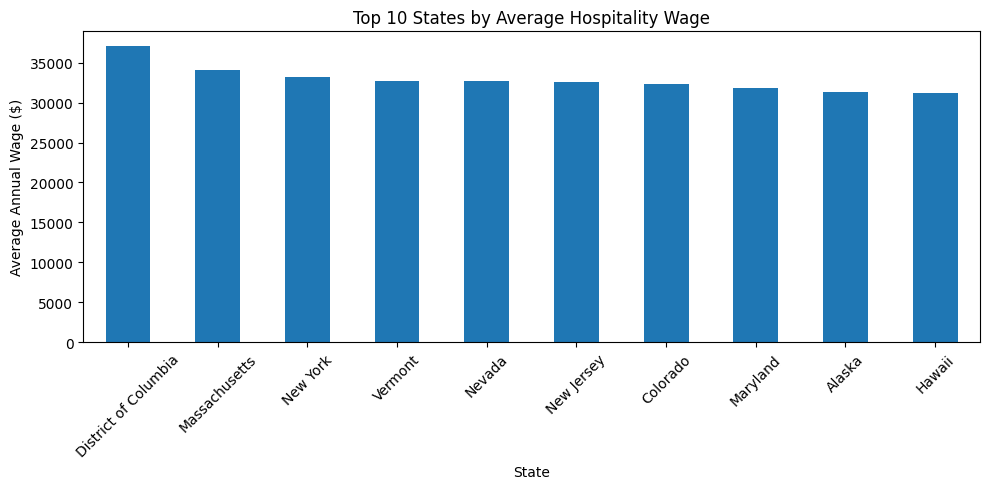

In [ ]:
state_avg_wage = (hospitality.groupby("area_title")["a_mean"].mean().sort_values(ascending=False).head(10))

print(state_avg_wage)

state_avg_wage.plot(kind="bar", figsize=(10, 5))

plt.title("Top 10 States by Average Hospitality Wage")
plt.xlabel("State")
plt.ylabel("Average Annual Wage ($)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


#### Q2 Which states in US have the highest and lowest hotel ratings?

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving hotel_reviews_combined_cleaned (1).csv to hotel_reviews_combined_cleaned (1).csv


In [ ]:
reviews = pd.read_csv('hotel_reviews_combined_cleaned (1).csv', dtype={'postalcode': 'string'})
print('Reviews loaded:', len(reviews))

Reviews loaded: 55698


/tmp/ipykernel_547/1007816597.py:1: DtypeWarning: Columns (2) have mixed types. Specify dtype option on import or set low_memory=False.
  reviews = pd.read_csv('hotel_reviews_combined_cleaned (1).csv', dtype={'postalcode': 'string'})


While cleaning our hotel_reviews data we noticed that some of the rivews were using rating scale up to 10, while most of them were on a 1-5 scale. So, before working on computing the average, we put all the rating to the same scale by deviding the ones that were bigger than five by two. 0 ratings were left out since the 1-5 rating scale does not inlcude 0.

In [ ]:
reviews['rating_original'] = reviews['reviews_rating']
above_5 = reviews['reviews_rating'] > 5
reviews['rating_converted'] = above_5

reviews.loc[above_5, 'reviews_rating'] = reviews.loc[above_5, 'reviews_rating'] / 2

print('Ratings converted:', above_5.sum())
print('Highest rating after conversion:', reviews['reviews_rating'].max())

Ratings converted: 357
Highest rating after conversion: 5.0


In [ ]:
rating_reviews = reviews[
    (reviews['reviews_rating'] >= 1) &
    (reviews['reviews_rating'] <= 5) &
    (reviews['country'] == 'US')].copy()

states = [
    'AL', 'AK', 'AZ', 'AR', 'CA', 'CO', 'CT', 'DE', 'FL', 'GA',
    'HI', 'ID', 'IL', 'IN', 'IA', 'KS', 'KY', 'LA', 'ME', 'MD',
    'MA', 'MI', 'MN', 'MS', 'MO', 'MT', 'NE', 'NV', 'NH', 'NJ',
    'NM', 'NY', 'NC', 'ND', 'OH', 'OK', 'OR', 'PA', 'RI', 'SC',
    'SD', 'TN', 'TX', 'UT', 'VT', 'VA', 'WA', 'WV', 'WI', 'WY']

valid_states = []
for state in rating_reviews['province']:
    valid_states.append(state in states)

rating_reviews = rating_reviews[valid_states]

state_average = rating_reviews.groupby('province')['reviews_rating'].mean()
state_count = rating_reviews.groupby('province')['reviews_rating'].count()

state_summary = pd.DataFrame({
    'average_rating': state_average,
    'review_count': state_count})

state_summary = state_summary[state_summary['review_count'] >= 100]
state_summary = state_summary.sort_values('average_rating', ascending=False)

print('Reviews used:', len(rating_reviews))
print('States with at least 100 reviews:', len(state_summary))
print('Average rating:', round(rating_reviews['reviews_rating'].mean(), 2))

Reviews used: 47264
States with at least 100 reviews: 44
Average rating: 3.9


States have different number reviews, one of our conditions for the analysis was for the state to have at least 100 reviews.

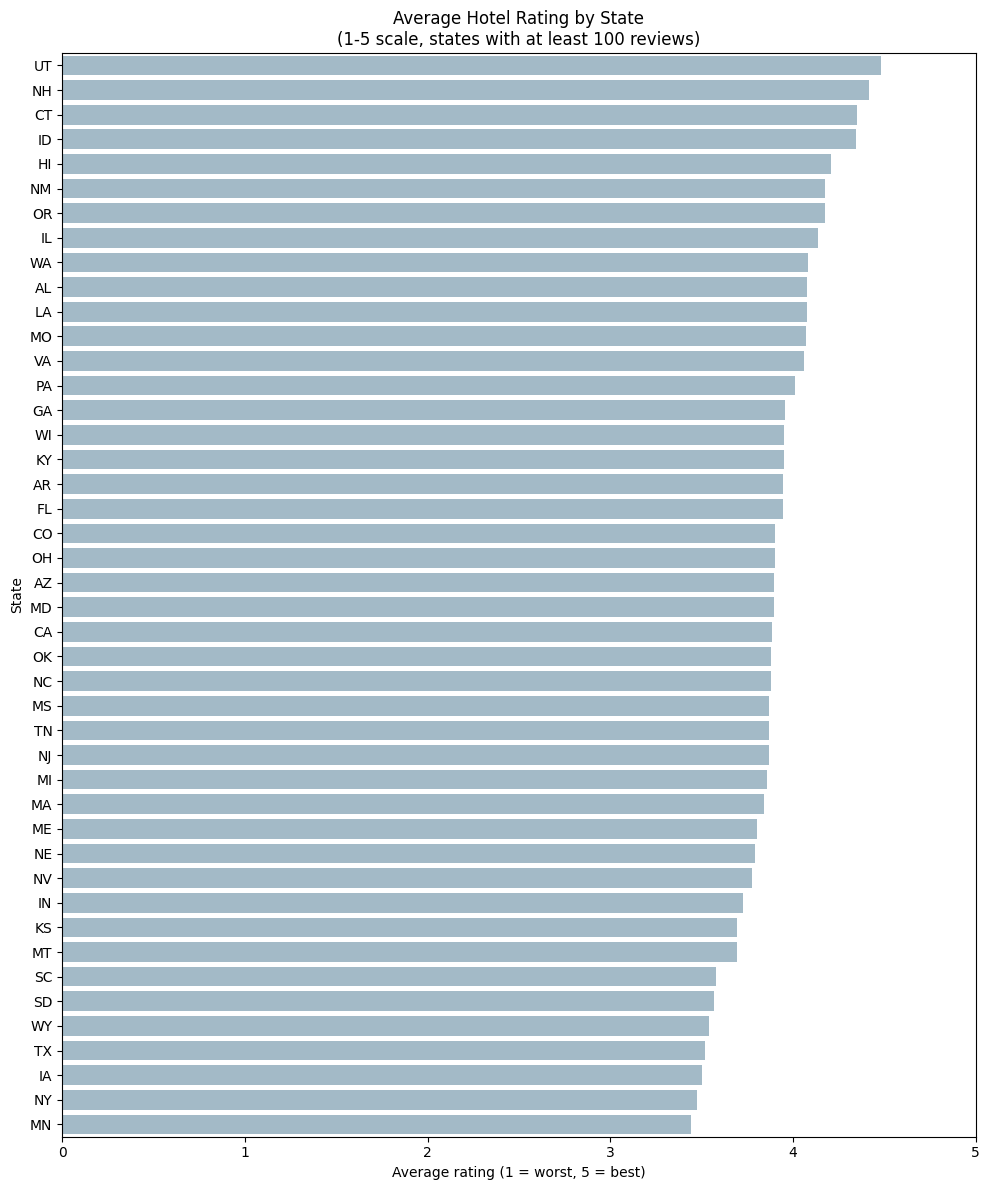

In [ ]:
fig, ax = plt.subplots(figsize=(10, 12))

sns.barplot(
    x=state_summary['average_rating'],
    y=state_summary.index,
    order=state_summary.index,
    color='#9DBBCD',
    ax=ax)

ax.set_title('Average Hotel Rating by State\n(1-5 scale, states with at least 100 reviews)')
ax.set_xlabel('Average rating (1 = worst, 5 = best)')
ax.set_ylabel('State')
ax.set_xlim(0, 5)

plt.tight_layout()
plt.show()

Summary: This graph shows the distin average rating by state, with  New Hampshire (4.60), Utah (4.53) and New Jersey (4.39) having the highest average ratings. South Carolina (3.17), Wyoming (3.20) and Texas (3.26) the lowest. The gap between the highest and lowest state is about 1.4 points, so ratings do vary across states, as we expected.

These averages are the basis for our further analysis. Joining them with data from question 1 and the following, will give us an opportunity to explore our main hypothesis (Whether states with higher wages for hospitality workers have higher hotel ratings).

### 5.2 Guest Complaints

#### Q3. What do guests complain about in lower rated reviews and how much does each complain lower the rating?

Hypothesis: The possibility or a room related issue being mentioned in the low ratings review is higher than staff problems.

This is information that hotel managers, customer service departments and housekeeping teams can use to evaluate what to focus on to better the customer experience and optimize their process.



Low ratings are in the range of 1-3, high ratings are 4-5.
We will count each key word as a part of a complaint only if it appears more often in low-rated reviews rathan than in high-rated ones. Some reviews consist of more than one key words and thus can be a part of multiple catehories of complaints.

In [ ]:
rated_with_text = reviews[
    (reviews['reviews_rating'] >= 1) &
    (reviews['reviews_rating'] <= 5)].copy()

rated_with_text = rated_with_text.dropna(subset=['reviews_text'])
rated_with_text['text_lower'] = rated_with_text['reviews_text'].str.lower()

rated_with_text['rating_group'] = 'Other'
rated_with_text.loc[rated_with_text['reviews_rating'] <= 3, 'rating_group'] = 'Low (1-3)'
rated_with_text.loc[rated_with_text['reviews_rating'] >= 4, 'rating_group'] = 'High (4-5)'

low = rated_with_text[rated_with_text['rating_group'] == 'Low (1-3)']
high = rated_with_text[rated_with_text['rating_group'] == 'High (4-5)']

print('Reviews with both text and a rating:', len(rated_with_text))
print('Low-rated reviews (1-3):', len(low))
print('High-rated reviews (4-5):', len(high))

Reviews with both text and a rating: 54471
Low-rated reviews (1-3): 16473
High-rated reviews (4-5): 37596


Here we have the number of reviews allocated into groups based on their level of rating


In [ ]:
def percent_with(phrase, texts):
    count = 0
    for review in texts:
        if phrase in review:
            count = count + 1
    return count / len(texts) * 100

test_words = ['dirty', 'rude', 'smell', 'broken', 'breakfast', 'location', 'parking', 'wifi', 'pillows']
low_percents = []
high_percents = []
for word in test_words:
    low_percents.append(round(percent_with(word, low['text_lower']), 1))
    high_percents.append(round(percent_with(word, high['text_lower']), 1))

pd.DataFrame({
    'word': test_words,
    '% of low-rated reviews': low_percents,
    '% of high-rated reviews': high_percents})

,word,% of low-rated reviews,% of high-rated reviews
0,dirty,8.2,0.5
1,rude,3.3,0.4
2,smell,10.3,1.4
3,broken,3.4,0.3
4,breakfast,19.3,26.7
5,location,11.6,18.4
6,parking,6.7,6.6
7,wifi,3.0,2.5
8,pillows,2.4,1.7


Here we can see how some of the chosen complaint words appear mostly in low-rated reviews. Some neutral words like "breakfast" are slightly more common in the high-rated reviews, so their presence does not necessarily indicate guests' dissatisfaction. That helped us be more specific in choosing our key words for complaint categories.


In [ ]:
keywords = {'Cleanliness': ['dirty', 'filthy', 'unclean', 'not clean', 'stain', 'hair in', 'hair on','mold', 'mildew', 'disgusting', 'gross', 'nasty', 'dingy'],
    'Pests': ['bed bug', 'bedbug', 'roach', 'bugs', 'spider', 'insect'],
    'Smell and smoke': ['smell', 'odor', 'musty', 'smoke', 'cigarette'],
    'Broken or outdated room': ['broken', "didn't work", 'did not work', 'not working', 'outdated','run down', 'worn', ' old and', 'very old', 'holes', 'peeling', 'leak', 'hot water'],
    'Staff and service': ['rude', 'unfriendly', 'unhelpful', 'unprofessional', 'poor service','bad service', 'refused', 'no one', 'nobody'],
    'Noise': ['noisy', 'loud', 'thin walls', 'paper thin', 'all night'],
    'Bed comfort': ['uncomfortable', 'mattress', 'lumpy', 'hard bed'],
    'Price and billing': ['refund', 'overpriced', 'not worth', 'money back', 'charged', 'rip off']}

categories = []
for category in keywords:
    categories.append(category)

for category in categories:
    matches = []
    for review in rated_with_text['text_lower']:
        found = False
        for phrase in keywords[category]:
            if phrase in review:
                found = True
                break
        matches.append(found)
    rated_with_text[category] = matches

rated_with_text['complaint_count'] = 0
for category in categories:
    rated_with_text['complaint_count'] = rated_with_text['complaint_count'] + rated_with_text[category]

rated_with_text['any_complaint'] = rated_with_text['complaint_count'] > 0

low = rated_with_text[rated_with_text['rating_group'] == 'Low (1-3)']
high = rated_with_text[rated_with_text['rating_group'] == 'High (4-5)']

print('Low-rated reviews with at least one complaint:', low['any_complaint'].sum())
print('Percent of low-rated reviews:', round(low['any_complaint'].mean() * 100, 1))
print('High-rated reviews with at least one complaint:', high['any_complaint'].sum())
print('Percent of high-rated reviews:', round(high['any_complaint'].mean() * 100, 1))

Low-rated reviews with at least one complaint: 8200
Percent of low-rated reviews: 49.8
High-rated reviews with at least one complaint: 3677
Percent of high-rated reviews: 9.8


These 8 main categories of complaints cover 5670 low-rated reviews ~ 48.2%, and about 9.4% of teh high-rated reviews, which shows taht they mostly cover the real complaints. Many of 3 rated reviews are appearing mixed  with no clear problem difinition, and were not used for our analysis.

In [ ]:
low = rated_with_text[rated_with_text['rating_group'] == 'Low (1-3)']
high = rated_with_text[rated_with_text['rating_group'] == 'High (4-5)']

low_counts = []
low_percents = []
high_percents = []
average_ratings = []

for category in categories:
    low_counts.append(low[category].sum())
    low_percents.append(low[category].mean() * 100)
    high_percents.append(high[category].mean() * 100)
    average_ratings.append(rated_with_text.loc[rated_with_text[category], 'reviews_rating'].mean())

complaints_summary = pd.DataFrame({'category': categories,'low_review_count': low_counts,'Low-rated reviews (1-3)': low_percents,'High-rated reviews (4-5)': high_percents,'average_rating_when_mentioned': average_ratings})

complaints_summary = complaints_summary.sort_values('Low-rated reviews (1-3)', ascending=False)
complaints_summary.round(2)

,category,low_review_count,Low-rated reviews (1-3),High-rated reviews (4-5),average_rating_when_mentioned
0,Cleanliness,3014,18.30,1.36,2.12
3,Broken or outdated room,2734,16.60,2.25,2.55
2,Smell and smoke,2214,13.44,1.88,2.52
5,Noise,1373,8.33,2.59,3.11
4,Staff and service,1126,6.84,0.81,2.35
7,Price and billing,938,5.69,0.72,2.33
1,Pests,739,4.49,0.41,2.05
6,Bed comfort,676,4.10,0.98,2.93


For each of the chosen 8 categories we can see the percentage of how often they appear in both low and high rated reviews. All of them are more common for low-rated ones. And we can see the average rating for complaints taht mention one of the categories teh most, the worst appearing for Pest, Cleanliness and Price&Billing

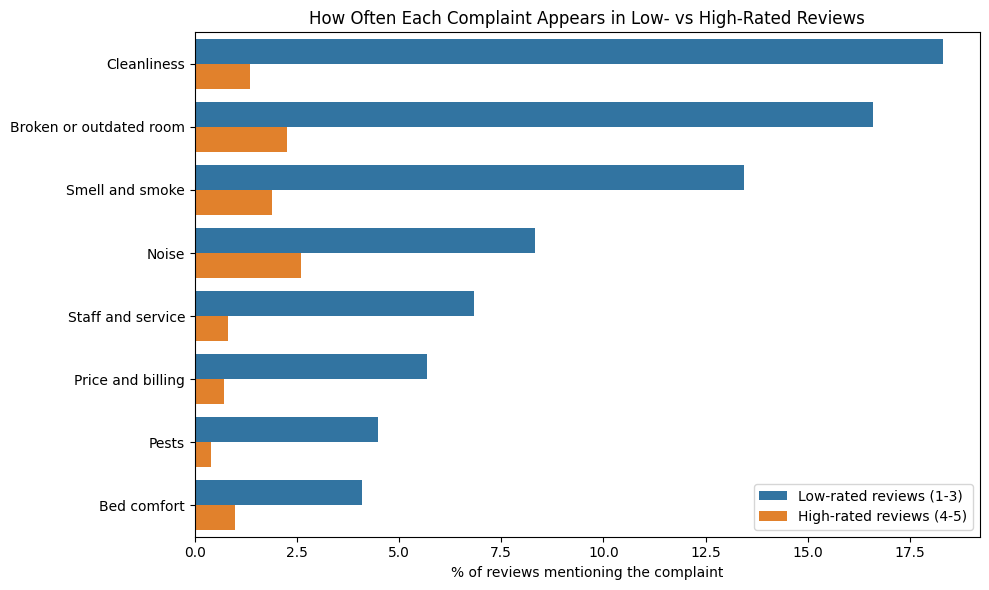

In [ ]:
chart_data = complaints_summary.melt(id_vars=['category'],value_vars=['Low-rated reviews (1-3)', 'High-rated reviews (4-5)'],var_name='review_group',value_name='percent')

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=chart_data, x='percent', y='category', hue='review_group', ax=ax)

ax.set_title('How Often Each Complaint Appears in Low- vs High-Rated Reviews')
ax.set_xlabel('% of reviews mentioning the complaint')
ax.set_ylabel('')
ax.set_xlim(left=0)
ax.legend(title='')
plt.tight_layout()
plt.show()

Cleanliness is the most common complaint and appears in about 20% of studied low-rated reviews. While stuff and service covers only about 6%.

#### Q4. How have average hotel customer ratings evolved over the years?

Hypothesis: Average hotel ratings were relatively stable between 2011 and 2016, with little fluctuations yearly.

The display of the ratings trend is relevant towards our overall analysis, to justify our foucs on the wages data of 2013. If ratings wpuld change a lot throught the years , the targeted comparison would be compromised.
For stakeholders and stuff such as hotel managers and hospitality investors, it also shows whether customer satisfaction across the industry has been improving, declining or holding steady over the years.

/tmp/ipykernel_547/1599882598.py:1: DtypeWarning: Columns (2) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('hotel_reviews_combined_cleaned (1).csv')


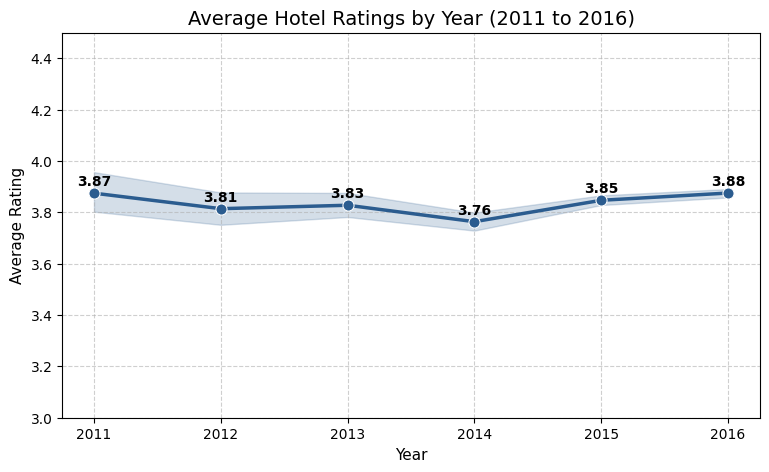

In [ ]:
df = pd.read_csv('hotel_reviews_combined_cleaned (1).csv')

above_5 = df['reviews_rating'] > 5
df.loc[above_5, 'reviews_rating'] = df.loc[above_5, 'reviews_rating'] / 2

df['reviews_date'] = pd.to_datetime(df['reviews_date'], errors='coerce')
df['year'] = df['reviews_date'].dt.year


df_meeting_condition = df[(df['year'] >= 2011) & (df['year'] <= 2016)]
df_meeting_condition = df_meeting_condition[(df_meeting_condition['reviews_rating'] >= 1) & (df_meeting_condition['reviews_rating'] <= 5)]

yearly_ratings = df_meeting_condition.groupby('year')['reviews_rating'].mean().reset_index()

plt.figure(figsize=(9, 5))
sns.lineplot(data=df_meeting_condition, x='year', y='reviews_rating',marker='o', color='#2b5c8f', linewidth=2.5, markersize=8)

plt.xlabel('Year', fontsize=11)
plt.ylabel('Average Rating', fontsize=11)
plt.ylim(3.0, 4.5)
plt.grid(True, linestyle='--', alpha=0.6)

for x, y in zip(yearly_ratings['year'], yearly_ratings['reviews_rating']):
    plt.text(x, y + 0.03, f'{y:.2f}', ha='center', fontsize=10, fontweight='bold')

plt.title('Average Hotel Ratings by Year (2011 to 2016)', fontsize=14)
plt.show()

In [ ]:
print(df_meeting_condition['year'].value_counts().sort_index())

year
2011.0     1128
2012.0     1570
2013.0     2806
2014.0     4976
2015.0    16537
2016.0    22026
Name: count, dtype: int64


Summary:

Between 2011 and 2016 hotels' average ratings stayed within a reasonably small range (3.68 to 3.82), with the biggest variance less than 0.2.
The confidance intervals for 2011 to 2014 overlap, so that small change over the years might have been caused by random variation rather than actual decline in customers' satisfaction.

Every year has at least 709 reviews.

Our hypothesis is supported by the results of this analysis: customer satisfaction was relatively stable, with no outright upward/downward tremd. One limitation to keep in mind, is that teh average each year comes from a mix of different hotels.

And thus ratings stayed within a narrow range over these years, comparing 2013 wage data with reviews from 2011 to 2016 is reasonable for the rest of our analysis.

### 5.3 Wage Exploration

#### Q6. How do hotel ratings compare in the 10 highest and lowest paying eligible states?

Hypothesis: The ten higher-wage eligible states will have higher average hotel ratings than the ten lower-wage eligible states.

Relevance: Q5 shows that ratings vary across years and review sources. With that context, this graph directly compares the average ratings of higher- and lower-wage eligible states using the same six-job wage index. State averages may hide differences between individual roles, so Q7 breaks wages down by occupation. This moves the analysis from a broad state comparison toward specific staffing decisions, without assuming that wages caused the rating differences.

In [ ]:
ranked_states = state_summary.sort_values('wage')
low_wage_states = ranked_states.head(10)
high_wage_states = ranked_states.tail(10)
fig, ax = plt.subplots(figsize=(12, 7.5))
ax.boxplot([low_wage_states.rating, high_wage_states.rating], positions=[1, 2], widths=0.4, patch_artist=True, boxprops={'facecolor': '#E2E8F0', 'edgecolor': navy}, medianprops={'color': navy, 'linewidth': 2}, showfliers=False)
for position, data, color in [(1, low_wage_states, gold), (2, high_wage_states, teal)]:
    for point_number, (state, row) in enumerate(data.sort_values('rating').iterrows()):
        wage_value = position + np.linspace(-0.11, 0.11, 10)[point_number]
        ax.scatter(wage_value, row.rating, s=48, color=color, zorder=3)
        if point_number in [0, 9]:
            ax.annotate(state, (wage_value, row.rating), xytext=(7, 0), textcoords='offset points', fontsize=8, va='center')
ax.set(xticks=[1, 2], xticklabels=['10 lowest-paying eligible states', '10 highest-paying eligible states'], ylabel='State mean overall rating (1–5)', ylim=(2.8, 4.6))
ax.grid(axis='y', alpha=0.18)
fig.tight_layout()
fig.savefig(graph_folder / 'Q6_state_wage_groups.png', dpi=240)
fig.savefig(graph_folder / 'Q6_state_wage_groups.svg')
plt.show()
plt.close(fig)
pd.concat([low_wage_states.assign(group='Low'), high_wage_states.assign(group='High')]).to_csv(graph_folder / 'Q6_chart_data.csv')

KeyError: 'wage'

In [ ]:
six_jobs = ['11-9081', '43-4081', '37-2012', '39-6011', '39-6012', '35-3031']

state_codes = {'Alabama':'AL','Alaska':'AK','Arizona':'AZ','Arkansas':'AR','California':'CA',
    'Colorado':'CO','Connecticut':'CT','Delaware':'DE','District of Columbia':'DC','Florida':'FL',
    'Georgia':'GA','Hawaii':'HI','Idaho':'ID','Illinois':'IL','Indiana':'IN','Iowa':'IA','Kansas':'KS',
    'Kentucky':'KY','Louisiana':'LA','Maine':'ME','Maryland':'MD','Massachusetts':'MA','Michigan':'MI',
    'Minnesota':'MN','Mississippi':'MS','Missouri':'MO','Montana':'MT','Nebraska':'NE','Nevada':'NV',
    'New Hampshire':'NH','New Jersey':'NJ','New Mexico':'NM','New York':'NY','North Carolina':'NC',
    'North Dakota':'ND','Ohio':'OH','Oklahoma':'OK','Oregon':'OR','Pennsylvania':'PA','Rhode Island':'RI',
    'South Carolina':'SC','South Dakota':'SD','Tennessee':'TN','Texas':'TX','Utah':'UT','Vermont':'VT',
    'Virginia':'VA','Washington':'WA','West Virginia':'WV','Wisconsin':'WI','Wyoming':'WY'}

six = state_detail[state_detail['occ_code'].isin(six_jobs)].copy()
six['a_mean'] = pd.to_numeric(six['a_mean'], errors='coerce')

wage_index = six.groupby('area_title')['a_mean'].mean().reset_index()
wage_index = wage_index.rename(columns={'a_mean': 'wage'})
wage_index['state'] = wage_index['area_title'].map(state_codes)

q6 = state_summary.reset_index()
q6 = q6.rename(columns={'province': 'state'})
q6 = pd.merge(q6, wage_index[['state', 'wage']], on='state', how='inner')
q6 = q6.sort_values('wage')

low10 = q6.head(10).copy()
low10['group'] = '10 lowest-paying states'
high10 = q6.tail(10).copy()
high10['group'] = '10 highest-paying states'

q6_plot = pd.concat([low10, high10], ignore_index=True)

print(q6_plot.groupby('group')['average_rating'].agg(['mean', 'count']).round(2))

low_avg = low10['average_rating'].mean()
high_avg = high10['average_rating'].mean()

plt.figure(figsize=(10, 7))
sns.scatterplot(data=q6_plot, x='average_rating', y='state', hue='group', s=120)
plt.axvline(low_avg, linestyle='--', color='tab:blue')
plt.axvline(high_avg, linestyle='--', color='tab:orange')
plt.title('Average Hotel Rating: 10 Lowest- vs. 10 Highest-Paying States')
plt.xlabel('State Average Rating (1-5)')
plt.ylabel('State (ordered from lowest to highest wage)')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig('Q6_state_wage_groups.png', dpi=300, bbox_inches='tight')
plt.show()

q6_plot.to_csv('Q6_chart_data.csv', index=False)

#### Q7. Which of the 6 hospitality related occupations has the highest and lowest wage?

Hypothesis: Lodging managers will have the highest average hourly wage and waitstaff the lowest among the six selected occupations.

Relevance: Q6 compares states using an average of six occupations, but that average hides how differently individual jobs are paid. This graph separates those jobs and identifies the higher- and lower-paid roles. Q8 then examines complaint flags connected to different work areas, allowing managers to consider pay levels alongside the kinds of guest issues reported. The connection is exploratory because a complaint cannot be assigned to a particular employee from these data.

In [ ]:
national_pay = wage_data[(wage_data.area_type == 1) & wage_data.naics.eq('000000') & (wage_data.own_code == 1235) & wage_data.occ_code.isin(job_names)].copy().sort_values('h_mean')
national_pay['role'] = national_pay.occ_code.map(job_names)
fig, ax = plt.subplots(figsize=(12, 7.5))
colors = []
for value in national_pay['h_mean']:
    if value == national_pay['h_mean'].max():
        colors.append(teal)
    elif value == national_pay['h_mean'].min():
        colors.append(gold)
    else:
        colors.append('#86ACBE')
ax.barh(national_pay['role'], national_pay['h_mean'], color=colors, height=0.6)
for row_number, wage_value in enumerate(national_pay.h_mean):
    ax.text(wage_value + 0.4, row_number, f'${wage_value:.2f}', va='center', weight='bold', color=navy)
ax.set(xlabel='Mean hourly wage (USD, 2013)', xlim=(0, national_pay.h_mean.max() * 1.2))
ax.grid(axis='x', alpha=0.16)
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(graph_folder / 'Q7_occupation_wages.png', dpi=240)
fig.savefig(graph_folder / 'Q7_occupation_wages.svg')
plt.show()
plt.close(fig)
national_pay[['occ_code', 'role', 'h_mean']].to_csv(graph_folder / 'Q7_chart_data.csv', index=False)

NameError: name 'wage_data' is not defined

### 5.4 Occupations & Complaints


#### Q8. Which occupation-related work areas appear most in complaint keyword flags?

Hypothesis: Cleanliness-related complaint keywords will appear more often than the other selected complaint categories in low-rated reviews.

Relevance: Q7 identifies pay differences across occupations. This graph adds the guest perspective by comparing complaint-keyword frequencies across related work areas. Q9 then brings the two ideas together by matching occupation wages with average ratings in reviews mentioning the related topic. This gives managers a progression from pay levels, to reported issues, to their possible association. Keyword flags are not confirmed complaints, and the Q9 topic matches also include positive mentions.

In [ ]:
reviews_with_text = hotel_reviews[hotel_reviews['reviews.text'].fillna('').str.strip().ne('')].copy()
groups = {'Low (1–3)': reviews_with_text.rating.le(3), 'High (4–5)': reviews_with_text.rating.ge(4)}
job_topics = {'Housekeeping / cleanliness': 'Cleanliness', 'Front desk / service': 'Service', 'Maintenance / facilities': 'Maintenance', 'Food staff / dining': 'Food'}
complaint_patterns = {'Cleanliness': '\\b(?:dirty|filthy|unclean|mold|mould|stains?)\\b|not clean', 'Service': '\\b(?:rude|unfriendly|unhelpful|unprofessional)\\b|poor service|bad service|slow service', 'Maintenance': '\\b(?:broken|leaking)\\b|not working|did not work|didn.t work', 'Food': 'bad breakfast|poor breakfast|terrible breakfast|cold food|cold breakfast|stale|undercooked|food poisoning'}
for topic, pattern in complaint_patterns.items():
    reviews_with_text[topic + '_complaint'] = reviews_with_text.text.str.contains(pattern, regex=True, na=False)
complaint_rows = []
for label, topic in job_topics.items():
    low_reviews = reviews_with_text.loc[groups['Low (1–3)']]
    high_reviews = reviews_with_text.loc[groups['High (4–5)']]
    low_percent = low_reviews[topic + '_complaint'].mean() * 100
    high_percent = high_reviews[topic + '_complaint'].mean() * 100
    complaint_rows.append([label, low_percent, high_percent])
complaint_rates = pd.DataFrame(complaint_rows, columns=['Work area', 'Low (1–3)', 'High (4–5)'])
complaint_rates = complaint_rates.set_index('Work area')
complaint_rates = complaint_rates.sort_values('Low (1–3)', ascending=False)
fig, ax = plt.subplots(figsize=(12, 7.5))
heatmap = ax.imshow(complaint_rates.values, cmap='YlGnBu', vmin=0, vmax=20, aspect='auto')
ax.set(xticks=[0, 1], xticklabels=[f'{source_reviews}\nn={int(groups[source_reviews].sum()):,}' for source_reviews in complaint_rates.columns], yticks=range(4), yticklabels=complaint_rates.index)
for row_number in range(4):
    for point_number in range(2):
        ax.text(point_number, row_number, f'{complaint_rates.iloc[row_number, point_number]:.1f}%', ha='center', va='center', fontsize=20, weight='bold', color='white' if complaint_rates.iloc[row_number, point_number] > 11 else navy)
fig.colorbar(heatmap, ax=ax, pad=0.025, label='% of reviews with a complaint flag')
fig.tight_layout()
fig.savefig(graph_folder / 'Q8_occupation_topic_heatmap.png', dpi=240)
fig.savefig(graph_folder / 'Q8_occupation_topic_heatmap.svg')
plt.show()
plt.close(fig)
complaint_rates.to_csv(graph_folder / 'Q8_chart_data.csv')

NameError: name 'hotel_reviews' is not defined

#### Q9. Does occupation pay relate to overall ratings in reviews mentioning its work area?

Hypothesis: States with higher wages for an occupation will have higher average ratings in reviews mentioning its related work area.

Relevance: Q7 describes occupation wages and Q8 identifies complaint patterns by work area. This graph connects them by comparing state-level job wages with overall ratings in reviews mentioning each related topic. Q10 then uses the same state wage index across service, cleanliness, location and value to compare the patterns on a common wage measure. This helps managers assess whether the association appears more relevant to operational topics, while recognising that topic-matched overall ratings are proxies rather than direct sentiment scores.

In [ ]:
jobs = [('Service', '43-4081', teal), ('Cleanliness', '37-2012', gold), ('Maintenance', '49-9071', '#A65D85'), ('Food', '35-2014', '#547AB5')]
fig, ax = plt.subplots(figsize=(12, 8))
scatter_tables = []
for topic, job_code, color in jobs:
    topic_reviews = reviews_with_text[reviews_with_text[topic]]
    graph_data = topic_reviews.groupby('province')['rating'].agg(['mean', 'count'])
    graph_data.columns = ['rating', 'n']
    graph_data = graph_data.join(job_wages[job_code].rename('wage'))
    graph_data = graph_data.dropna(subset=['wage'])
    graph_data = graph_data[graph_data['n'] >= 30]
    correlation, p_value = pearsonr(graph_data['wage'], graph_data['rating'])
    label = f'{topic}: r = {correlation:.2f}, {len(graph_data)} states'
    ax.scatter(graph_data['wage'], graph_data['rating'], color=color, label=label, s=65, alpha=0.75, edgecolor='white', linewidth=0.5)
    slope, intercept = np.polyfit(graph_data['wage'], graph_data['rating'], 1)
    wage_range = np.array([graph_data['wage'].min(), graph_data['wage'].max()])
    ax.plot(wage_range, slope * wage_range + intercept, color=color, linewidth=2)
    graph_data['topic'] = topic
    graph_data['r'] = correlation
    graph_data['p_value'] = p_value
    scatter_tables.append(graph_data)
ax.set_xlabel('2013 job wage ($ per hour)')
ax.set_ylabel('Average overall review rating (1–5)')
ax.set_ylim(1, 5.1)
ax.grid(alpha=0.15)
ax.legend(title='Review category', loc='lower left', fontsize=10, frameon=True)
fig.tight_layout()
fig.savefig(graph_folder / 'Q9_occupation_wage_scatter.png', dpi=240)
fig.savefig(graph_folder / 'Q9_occupation_wage_scatter.svg')
plt.show()
plt.close(fig)
pd.concat(scatter_tables).to_csv(graph_folder / 'Q9_chart_data.csv')

NameError: name 'teal' is not defined

#### Q10. Does the wage index correlate more strongly with ratings in service/cleanliness reviews than location/value reviews?

Hypothesis: The state wage index will have a stronger positive correlation with ratings in service and cleanliness reviews than in location and value reviews.

Relevance: Q9 compares different occupation wages with ratings in related review topics. This graph follows by using one consistent state wage index across all four topics, allowing a clearer descriptive comparison of service and cleanliness with location and value. Together, Q6 through Q10 move from state-level averages to individual jobs, complaint patterns and topic-specific associations. This helps managers judge whether the evidence supports further investigation of staffing and pay; it does not establish causation or formally test whether the correlations differ.

In [ ]:
results = []
for topic in ['Service', 'Cleanliness', 'Location', 'Value']:
    graph_data = reviews_with_text[reviews_with_text[topic]].groupby('province').agg(rating=('rating', 'mean'), n=('rating', 'size')).join(state_wage_index)
    graph_data = graph_data[(graph_data.n >= 30) & graph_data.wage.notna()]
    result = pearsonr(graph_data['wage'], graph_data['rating'])
    correlation = result.statistic
    p_value = result.pvalue
    interval = result.confidence_interval(confidence_level=0.95)
    lower_limit = interval.low
    upper_limit = interval.high
    results.append([topic, correlation, lower_limit, upper_limit, len(graph_data), p_value])
correlation_table = pd.DataFrame(results, columns=['topic', 'r', 'lower', 'upper', 'states', 'p_value'])
fig, ax = plt.subplots(figsize=(12, 7.5))
for row_number, row in correlation_table.iterrows():
    color = teal if row_number < 2 else gold
    ax.errorbar(row.r, row_number, xerr=[[row.r - row.lower], [row.upper - row.r]], fmt='o', color=color, ms=9, capsize=5, lw=2)
    ax.text(0.97, row_number, f'r={row.r:+.2f}  |  n={row.states}', ha='right', va='center', fontsize=10, color=navy)
ax.axvline(0, color='#94A3B8', ls='--')
ax.set(yticks=range(4), yticklabels=['Service', 'Cleanliness', 'Location', 'Value'], xlim=(-1, 1), ylim=(3.7, -0.7), xlabel='Pearson r  (negative ← association → positive)')
ax.grid(axis='x', alpha=0.13)
fig.tight_layout()
fig.savefig(graph_folder / 'Q10_topic_correlation.png', dpi=240)
fig.savefig(graph_folder / 'Q10_topic_correlation.svg')
plt.show()
plt.close(fig)
correlation_table.to_csv(graph_folder / 'Q10_chart_data.csv', index=False)

NameError: name 'reviews_with_text' is not defined

### 5.5 Extreme Reviews & Lowest Wages

#### Q11. Do higher wage states have fewer very negative reviews even when their average rating are similar?

Hypothesis: States with higher wages are likely to have fewer negative reviews even if the average ratings are similar.

Important detail: the median wage is calculated only among the states left in the analysis, after dropping states with fewer than 100 reviews and states that didn’t match between the two datasets. So “high” and “low” are relative to the states in your graph, not all 50. And the "low" vs "high" wages are calculated by taking the median wages across states, and everything below it is low and everything above it is high.

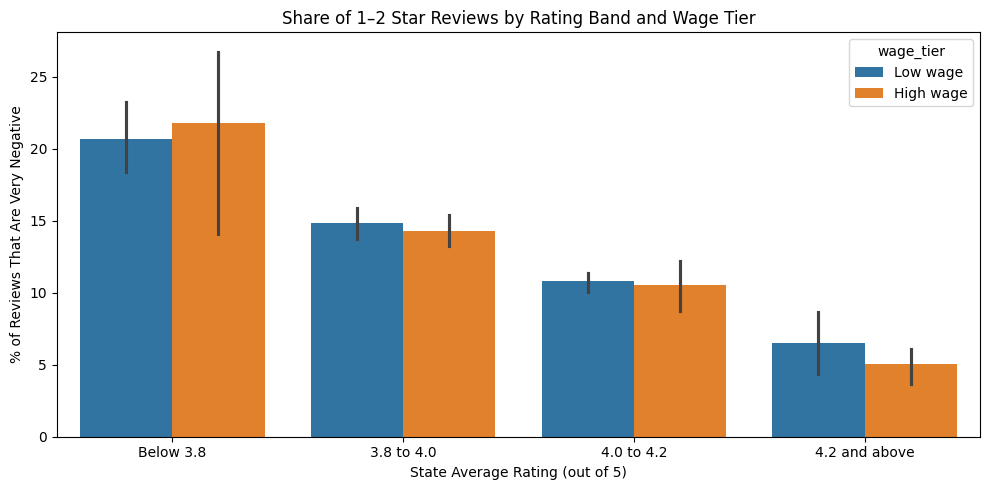

In [ ]:
hospitality = hospitality.copy()
reviews['rating_5'] = pd.to_numeric(reviews['reviews_rating'], errors='coerce')
reviews.loc[reviews['rating_5'] > 5, 'rating_5'] = reviews['rating_5'] / 2

state_abbreviated = ['AL','AK','AZ','AR','CA','CO','CT','DE','DC','FL','GA','HI','ID','IL','IN','IA','KS','KY',
               'LA','ME','MD','MA','MI','MN','MS','MO','MT','NE','NV','NH','NJ','NM','NY','NC','ND','OH',
               'OK','OR','PA','RI','SC','SD','TN','TX','UT','VT','VA','WA','WV','WI','WY']

reviews_update = reviews[(reviews['country'] == 'US') & (reviews['province'].isin(state_abbreviated))]
reviews_update = reviews_update[(reviews_update['rating_5'] >= 1) & (reviews_update['rating_5'] <= 5)].copy()

reviews_update['very_negative'] = (reviews_update['rating_5'] <= 2).astype(int)

avg_rate = reviews_update.groupby('province')['rating_5'].agg(['mean', 'count'])
avg_rate = avg_rate.rename(columns={'mean': 'avg_rating', 'count': 'n_reviews'})

percent_negative = reviews_update.groupby('province')['very_negative'].mean() * 100

state_reviews = avg_rate.reset_index()
state_reviews['pct_very_negative'] = percent_negative.values
state_reviews = state_reviews.rename(columns={'province': 'state'})

state_and_abbreviation = {'Alabama':'AL','Alaska':'AK','Arizona':'AZ','Arkansas':'AR','California':'CA',
    'Colorado':'CO','Connecticut':'CT','Delaware':'DE','District of Columbia':'DC','Florida':'FL',
    'Georgia':'GA','Hawaii':'HI','Idaho':'ID','Illinois':'IL','Indiana':'IN','Iowa':'IA','Kansas':'KS',
    'Kentucky':'KY','Louisiana':'LA','Maine':'ME','Maryland':'MD','Massachusetts':'MA','Michigan':'MI',
    'Minnesota':'MN','Mississippi':'MS','Missouri':'MO','Montana':'MT','Nebraska':'NE','Nevada':'NV',
    'New Hampshire':'NH','New Jersey':'NJ','New Mexico':'NM','New York':'NY','North Carolina':'NC',
    'North Dakota':'ND','Ohio':'OH','Oklahoma':'OK','Oregon':'OR','Pennsylvania':'PA','Rhode Island':'RI',
    'South Carolina':'SC','South Dakota':'SD','Tennessee':'TN','Texas':'TX','Utah':'UT','Vermont':'VT',
    'Virginia':'VA','Washington':'WA','West Virginia':'WV','Wisconsin':'WI','Wyoming':'WY'}

hospitality['a_mean'] = pd.to_numeric(hospitality['a_mean'], errors='coerce')
state_wages = hospitality.groupby('area_title')['a_mean'].mean().reset_index()
state_wages = state_wages.rename(columns={'a_mean': 'avg_wage'})
state_wages['state'] = state_wages['area_title'].map(state_and_abbreviation)

state = pd.merge(state_reviews, state_wages[['state', 'avg_wage']], on='state', how='inner')
state = state[state['n_reviews'] >= 100]

median_wage = state['avg_wage'].median()
state['wage_tier'] = 'Low wage'
state.loc[state['avg_wage'] >= median_wage, 'wage_tier'] = 'High wage'

state['rating_band'] = 'Below 3.8'
state.loc[state['avg_rating'] >= 3.8, 'rating_band'] = '3.8 to 4.0'
state.loc[state['avg_rating'] >= 4.0, 'rating_band'] = '4.0 to 4.2'
state.loc[state['avg_rating'] >= 4.2, 'rating_band'] = '4.2 and above'

plt.figure(figsize=(10, 5))
sns.barplot(data=state, x='rating_band', y='pct_very_negative', hue='wage_tier',
            order=['Below 3.8', '3.8 to 4.0', '4.0 to 4.2', '4.2 and above'])
plt.title('Share of 1–2 Star Reviews by Rating Band and Wage Tier')
plt.xlabel('State Average Rating (out of 5)')
plt.ylabel('% of Reviews That Are Very Negative')
plt.tight_layout()
plt.show()

In [ ]:
print(state.sort_values('avg_rating')[['state', 'avg_rating', 'avg_wage', 'wage_tier', 'n_reviews']])

   state  avg_rating      avg_wage  wage_tier  n_reviews
23    MN    3.441860  29802.083333  High wage        516
34    NY    3.475472  33220.400000  High wage       1590
12    IA    3.503987  26494.583333   Low wage        627
43    TX    3.521130  27286.000000   Low wage       2584
50    WY    3.538462  26920.588235   Low wage        195
41    SD    3.570652  27039.047619   Low wage        184
40    SC    3.581443  26723.043478   Low wage        970
26    MT    3.693780  26097.894737   Low wage        418
16    KS    3.695402  26706.521739   Low wage        174
15    IN    3.724167  26747.500000   Low wage        480
33    NV    3.773704  32694.761905  High wage       1061
29    NE    3.794979  26047.727273   Low wage        239
21    ME    3.801570  27120.000000   Low wage        446
19    MA    3.840072  34079.166667  High wage        972
22    MI    3.856357  28207.826087  High wage       1054
31    NJ    3.866822  32627.083333  High wage        428
42    TN    3.867757  27183.750

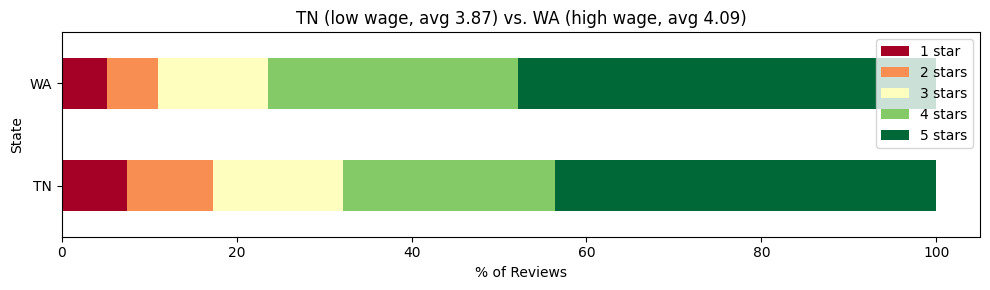

In [ ]:
high_state = 'WA'
low_state = 'TN'

reviews_update['stars'] = reviews_update['rating_5'].round().astype(int)

pair = reviews_update[reviews_update['province'].isin([high_state, low_state])]

percentage = pd.crosstab(pair['province'], pair['stars'], normalize='index') * 100
percentage = percentage.rename(columns={1: '1 star', 2: '2 stars', 3: '3 stars', 4: '4 stars', 5: '5 stars'})
percentage = percentage.loc[[low_state, high_state]]

high_average = state.loc[state['state'] == high_state, 'avg_rating'].values[0]
low_average = state.loc[state['state'] == low_state, 'avg_rating'].values[0]


ax = percentage.plot(kind='barh', stacked=True, figsize=(10, 3), colormap='RdYlGn')
plt.title('{} (low wage, avg {:.2f}) vs. {} (high wage, avg {:.2f})'.format(
    low_state, low_average, high_state, high_average))
plt.xlabel('% of Reviews')
plt.ylabel('State')
plt.legend()
plt.tight_layout()
plt.show()

#### Q12. How do average wages compare to 10th percentile wages across lower paid hospitality occupations?

Hypothesis: An expected wage disparity when looking between the wage mean and 10th percentile wages across hospitality occupations.

This is relevant to stakeholders such as hotel managers and hospitality employees in being more informed on compensation. It helps in highlighting patterns in guest satisfaction and further showing context in understanding if employee wage affects hotel ratings.

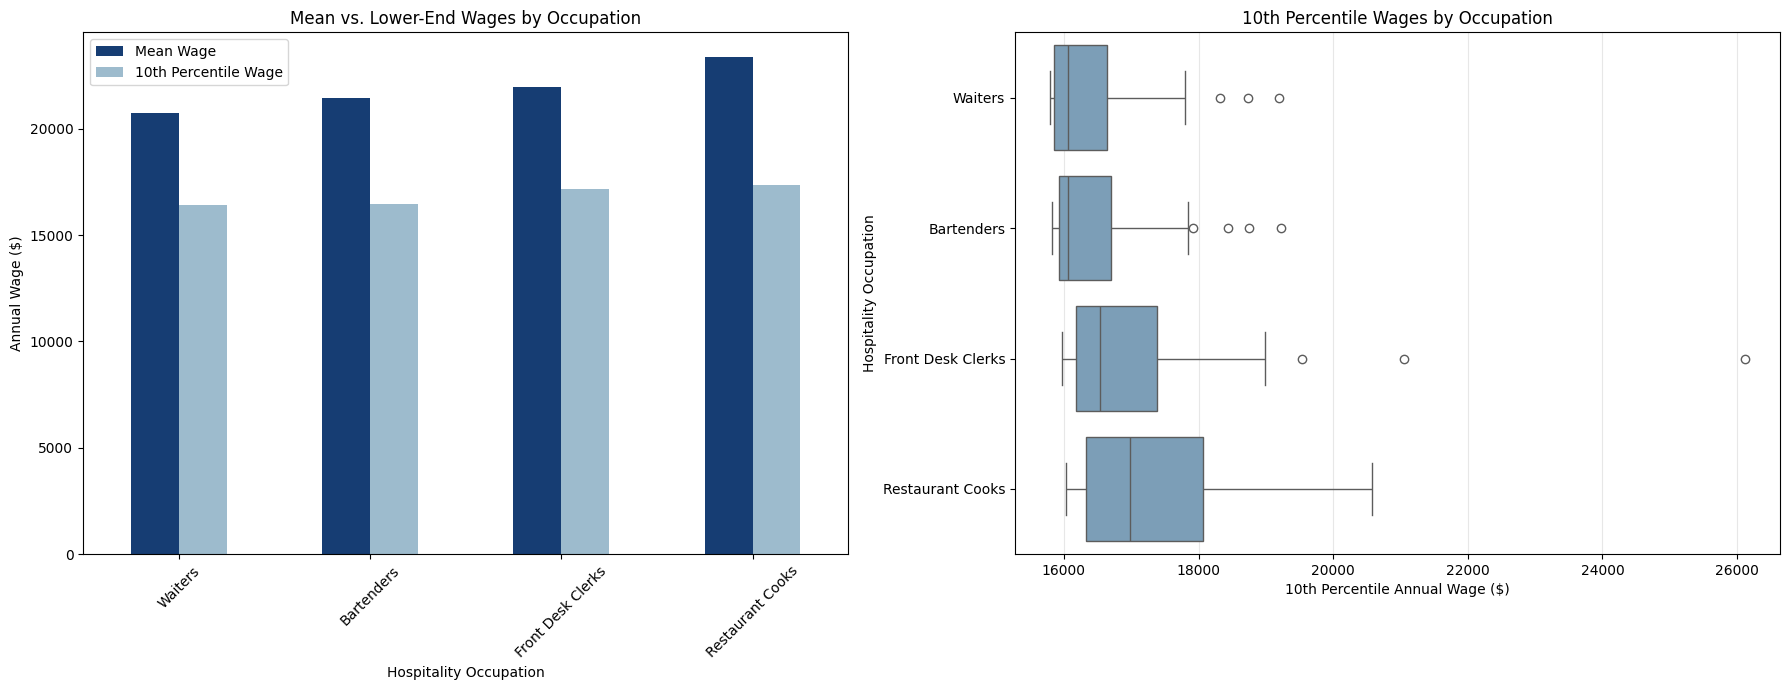

In [ ]:
occupations = ["Hotel, Motel, and Resort Desk Clerks", "Maids and Housekeeping Cleaners", "Waiters and Waitresses","Bartenders", "Dishwashers","Cooks, Restaurant"]

occupation_wages = hospitality[(hospitality["occ_title"].isin(occupations)) & (hospitality["area_type_label"] == "State")].copy()

occupation_wages["a_mean"] = pd.to_numeric(occupation_wages["a_mean"], errors="coerce")

occupation_wages["a_pct10"] = pd.to_numeric(occupation_wages["a_pct10"], errors="coerce")

occupation_wages["occupation"] = occupation_wages["occ_title"].replace({
    "Hotel, Motel, and Resort Desk Clerks": "Front Desk Clerks",
    "Maids and Housekeeping Cleaners": "Housekeepers",
    "Waiters and Waitresses": "Waiters",
    "Bartenders": "Bartenders",
    "Dishwashers": "Dishwashers",
    "Cooks, Restaurant": "Restaurant Cooks"})

wage_comparison = occupation_wages.groupby("occupation")[["a_mean", "a_pct10"]].mean()

wage_comparison = wage_comparison.sort_values("a_mean")

fig, ax = plt.subplots(1, 2, figsize=(18, 7))

# Graph 1
wage_comparison.plot(kind="bar",ax=ax[0],color=["#163D73", "#9DBBCD"])

ax[0].set_title("Mean vs. Lower-End Wages by Occupation")
ax[0].set_xlabel("Hospitality Occupation")
ax[0].set_ylabel("Annual Wage ($)")
ax[0].tick_params(axis="x", rotation=45)
ax[0].legend(["Mean Wage", "10th Percentile Wage"])

# Graph 2: box plot by occupation
sns.boxplot(data=occupation_wages,x="a_pct10", y="occupation", order=wage_comparison.index,color="#72A0C1",ax=ax[1])

ax[1].set_title("10th Percentile Wages by Occupation")
ax[1].set_xlabel("10th Percentile Annual Wage ($)")
ax[1].set_ylabel("Hospitality Occupation")
ax[1].grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()


The code looks into the mean of the 4 lowest paid hospitality and filters by occupation.

Summary: According to the graph, Restaurant Cooks have the highest average wage between the four lowest paying occupations at approximately \$29000. This is a stark difference in comparision to waiters who average at \$20000. It highlights the compensation variations amongst the different hospitality occupations.

### 5.6 Full Picture

#### Q13. What is more strongly linked to a state's hotel rating: hospitality wages or room condition complaints?

Hypothesis: Room-condition complaints have bigger influence on state average hotels' ratings than hospitality wages do.



In [ ]:
state_wage = hospitality.groupby('area_title')['a_mean'].mean().reset_index()
state_wage.columns = ['state_name', 'average_hospitality_wage']

state_codes = {'Alabama': 'AL', 'Alaska': 'AK', 'Arizona': 'AZ', 'Arkansas': 'AR', 'California': 'CA',
    'Colorado': 'CO', 'Connecticut': 'CT', 'Delaware': 'DE', 'Florida': 'FL', 'Georgia': 'GA',
    'Hawaii': 'HI', 'Idaho': 'ID', 'Illinois': 'IL', 'Indiana': 'IN', 'Iowa': 'IA',
    'Kansas': 'KS', 'Kentucky': 'KY', 'Louisiana': 'LA', 'Maine': 'ME', 'Maryland': 'MD',
    'Massachusetts': 'MA', 'Michigan': 'MI', 'Minnesota': 'MN', 'Mississippi': 'MS', 'Missouri': 'MO',
    'Montana': 'MT', 'Nebraska': 'NE', 'Nevada': 'NV', 'New Hampshire': 'NH', 'New Jersey': 'NJ',
    'New Mexico': 'NM', 'New York': 'NY', 'North Carolina': 'NC', 'North Dakota': 'ND', 'Ohio': 'OH',
    'Oklahoma': 'OK', 'Oregon': 'OR', 'Pennsylvania': 'PA', 'Rhode Island': 'RI', 'South Carolina': 'SC',
    'South Dakota': 'SD', 'Tennessee': 'TN', 'Texas': 'TX', 'Utah': 'UT', 'Vermont': 'VT',
    'Virginia': 'VA', 'Washington': 'WA', 'West Virginia': 'WV', 'Wisconsin': 'WI', 'Wyoming': 'WY'}

codes = []
for name in state_wage['state_name']:
    if name in state_codes:
        codes.append(state_codes[name])
    else:
        codes.append('Not a state')

state_wage['province'] = codes
state_wage = state_wage[state_wage['province'] != 'Not a state']

print('States with wage data:', len(state_wage))
state_wage.sort_values('average_hospitality_wage', ascending=False).head()

States with wage data: 50


,state_name,average_hospitality_wage,province
21,Massachusetts,34079.166667,MA
32,New York,33220.400000,NY
45,Vermont,32702.608696,VT
28,Nevada,32694.761905,NV
30,New Jersey,32627.083333,NJ


Here we have a list with hospitality roles wages for all states.

In [ ]:
room_categories = ['Cleanliness', 'Pests', 'Smell and smoke', 'Broken or outdated room']

us_text = rated_with_text[rated_with_text['country'] == 'US'].copy()

keywords = {'Cleanliness': ['dirty', 'filthy', 'unclean', 'not clean', 'stain', 'hair in', 'hair on', 'mold', 'mildew', 'disgusting', 'gross', 'nasty', 'dingy'],'Pests': ['bed bug', 'bedbug', 'roach', 'bugs', 'spider', 'insect'],'Smell and smoke': ['smell', 'odor', 'musty', 'smoke', 'cigarette'],'Broken or outdated room': ['broken', "didn't work", 'did not work', 'not working', 'outdated', 'run down', 'worn', ' old and', 'very old', 'holes', 'peeling', 'leak', 'hot water']}

for category in room_categories:
    if category not in us_text.columns:
        us_text[category] = us_text['text_lower'].apply(lambda review: any(phrase in str(review) for phrase in keywords[category]))

us_text['room_complaint'] = False
for category in room_categories:
    us_text['room_complaint'] = us_text['room_complaint'] | us_text[category]

state_complaints = us_text.groupby('province')['room_complaint'].mean() * 100
state_complaints = state_complaints.reset_index()
state_complaints.columns = ['province', 'room_complaint_percent']

state_complaints.sort_values('room_complaint_percent', ascending=False).head()

,province,room_complaint_percent
55,Flournoy,100.0
49,Estes,100.0
18,Burr Oak,100.0
104,Lorenzo,100.0
146,Palm Springs Municipal Airpo,100.0


 Here we calculated the percentage of reviews that mention at least one of the room-condition complaint (cleanliness, pests, smell and smoke, or broken or outdated room).

In [ ]:
ratings_table = state_summary.reset_index()

state_table = pd.merge(ratings_table, state_wage[['province', 'average_hospitality_wage']], on='province', how='inner')
state_table = pd.merge(state_table, state_complaints, on='province', how='inner')

print('States in the joined table:', len(state_table))
print('Wage range: $', round(state_table['average_hospitality_wage'].min()),
      'to $', round(state_table['average_hospitality_wage'].max()))
print('Room-complaint range:', round(state_table['room_complaint_percent'].min(), 1),
      '% to', round(state_table['room_complaint_percent'].max(), 1), '%')

state_table.sort_values('average_rating', ascending=False).round(2)

States in the joined table: 44
Wage range: $ 24110 to $ 34079
Room-complaint range: 4.5 % to 23.2 %


,province,average_rating,review_count,average_hospitality_wage,room_complaint_percent
0,UT,4.48,356,28526.52,4.49
1,NH,4.42,139,27729.05,5.76
2,CT,4.35,221,29917.73,5.88
3,ID,4.34,207,26467.92,5.80
4,HI,4.21,703,31190.00,6.69
5,NM,4.17,189,26420.91,7.41
6,OR,4.17,837,28584.17,9.22
7,IL,4.14,1534,28735.42,10.56
8,WA,4.09,1454,30762.92,10.18
9,AL,4.08,429,26076.52,10.28


Here we took the 42 states from question 2 and matched them with wages and complaints.

In [ ]:
correlations = state_table[['average_rating', 'average_hospitality_wage', 'room_complaint_percent']].corr()

wage_correlation = correlations.loc['average_hospitality_wage', 'average_rating']
complaint_correlation = correlations.loc['room_complaint_percent', 'average_rating']

print('Correlation of rating with hospitality wage:', round(wage_correlation, 2))
print('Correlation of rating with room-complaint %:', round(complaint_correlation, 2))
correlations.round(2)

Correlation of rating with hospitality wage: 0.03
Correlation of rating with room-complaint %: -0.9


,average_rating,average_hospitality_wage,room_complaint_percent
average_rating,1.00,0.03,-0.90
average_hospitality_wage,0.03,1.00,-0.03
room_complaint_percent,-0.90,-0.03,1.00


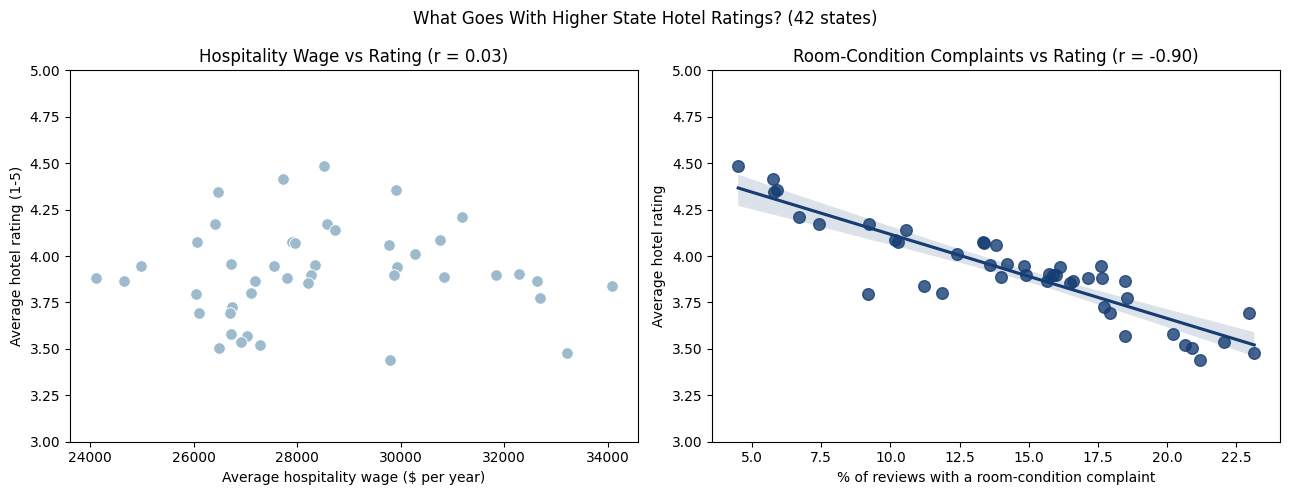

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))

sns.scatterplot(data=state_table, x='average_hospitality_wage', y='average_rating',
                color='#9DBBCD', s=70, ax=ax[0])
ax[0].set_title(f'Hospitality Wage vs Rating (r = {wage_correlation:.2f})')
ax[0].set_xlabel('Average hospitality wage ($ per year)')
ax[0].set_ylabel('Average hotel rating (1-5)')
ax[0].set_ylim(3, 5)


sns.regplot(data=state_table, x='room_complaint_percent', y='average_rating',
                color='#163D73', scatter_kws={'s': 70}, ax=ax[1])
ax[1].set_title(f'Room-Condition Complaints vs Rating (r = {complaint_correlation:.2f})')
ax[1].set_xlabel('% of reviews with a room-condition complaint')
ax[1].set_ylabel('Average hotel rating')
ax[1].set_ylim(3, 5)

plt.suptitle('What Goes With Higher State Hotel Ratings? (42 states)')
plt.tight_layout()
plt.show()

Summary: Room-condition related complaints have a stronger link to hotel ratings (r = −0.89) than hospitality wages (r = −0.03). Which suports our hypothesis for this comparison.

For stakeholders:
Main takeaway can be that: raising wages alone is unlikely to raise ratings. In this data, state wage levels show no real link with guest satisfactio. According to our analysis room condition is where ratings can be either won or lost.
However, it is important to remeber that wages don't matter at all. Fair pay can still affect staff retention and service quality in ways a state-level average cannot show.

## 6. Conclusion

## 7. Challenges

## 8. AI Disclosure